In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import shutil

print("Available Colab disk space:")
print(f"{shutil.disk_usage('/content').free / (1024**3):.2f} GB free")

print("\nDataset destination: /content")


Available Colab disk space:
70.28 GB free

Dataset destination: /content


In [ ]:

import requests
from bs4 import BeautifulSoup

url = "https://patricktum.github.io/cloud_removal/sen12mscr/"

response = requests.get(url, timeout=30)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

print("Page title:", soup.title.get_text(strip=True))
print("\nLinks mentioning downloads, data or files:\n")

for link in soup.find_all("a", href=True):
    text = link.get_text(" ", strip=True)
    href = link["href"]

    if any(word in (text + " " + href).lower()
           for word in ["download", "data", ".zip", ".tar", "sen12"]):
        print(f"{text or '[link]'}: {href}")


Page title: SEN12MS-CR Dataset

Links mentioning downloads, data or files:

SEN12MS data set: https://github.com/schmitt-muc/SEN12MS
SEN12MS-CR: https://github.com/PatrickTUM/SEN12MS-CR-TS/blob/2af933422f58fdfd6fc826ba3a827b288aad36fb/data/dataLoader.py#L372
SEN12MS-CR-TS: https://github.com/PatrickTUM/SEN12MS-CR-TS/blob/2af933422f58fdfd6fc826ba3a827b288aad36fb/data/dataLoader.py#L106
here: https://github.com/PatrickTUM/SEN12MS-CR-TS/blob/master/util/dl_data.sh
here: https://github.com/PatrickTUM/SEN12MS-CR-TS
SEN12MS-CR: #";


In [ ]:

from pathlib import Path

# Change this to your actual dataset folder
DATASET_DIR = Path("/content/SEN12MS-CR")

if not DATASET_DIR.exists():
    print("Dataset folder not found:", DATASET_DIR)
    print("Update DATASET_DIR to the correct location.")
else:
    print("Dataset folder:", DATASET_DIR)

    for path in sorted(DATASET_DIR.iterdir()):
        kind = "DIR " if path.is_dir() else "FILE"
        print(kind, path.name)


Dataset folder not found: /content/SEN12MS-CR
Update DATASET_DIR to the correct location.


In [ ]:

from collections import Counter
from pathlib import Path

DATASET_DIR = Path("/content/SEN12MS-CR")  # Update if needed

if DATASET_DIR.exists():
    files = [p for p in DATASET_DIR.rglob("*") if p.is_file()]

    print("Total files:", len(files))
    print("\nFile types:")
    for ext, count in Counter(
        p.suffix.lower() or "[no extension]" for p in files
    ).most_common():
        print(f"{ext}: {count}")

    print("\nFirst 60 file paths:")
    for p in files[:60]:
        print(p.relative_to(DATASET_DIR))
else:
    print("Folder not found. Update DATASET_DIR first.")


Folder not found. Update DATASET_DIR first.


In [ ]:

import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin

url = "https://patricktum.github.io/cloud_removal/sen12mscr/"

response = requests.get(url, timeout=30)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

print("PAGE:", soup.title.get_text(strip=True))
print("SOURCE:", url)

print("\n--- LINKS ON THE DATASET PAGE ---")

for a in soup.find_all("a", href=True):
    name = a.get_text(" ", strip=True) or "(unnamed link)"
    link = urljoin(url, a["href"])
    print(f"{name}\n  {link}")


PAGE: SEN12MS-CR Dataset
SOURCE: https://patricktum.github.io/cloud_removal/sen12mscr/

--- LINKS ON THE DATASET PAGE ---
SEN12MS data set
  https://github.com/schmitt-muc/SEN12MS
(Enomoto et al., 2017)
  https://openaccess.thecvf.com/content_cvpr_2017_workshops/w18/html/Enomoto_Filmy_Cloud_Removal_CVPR_2017_paper.html
(Grohnfeldt et al., 2018)
  https://ieeexplore.ieee.org/document/8519215
(Bermudez et al., 2018)
  https://www.isprs-ann-photogramm-remote-sens-spatial-inf-sci.net/IV-1/5/2018/
(Pan, 2020)
  https://arxiv.org/abs/2009.13015
(Gao et al., 2020)
  https://www.mdpi.com/2072-4292/12/1/191
(Meraner et al., 2020)
  https://www.sciencedirect.com/science/article/pii/S0924271620301398
(Xu et al., 2022)
  https://www.sciencedirect.com/science/article/pii/S0924271622002064
(Ebel et al., 2023)
  https://arxiv.org/abs/2304.05464
(Huang et al., 2024)
  https://doi.org/10.1016/j.eswa.2025.129859
(Zou et al., 2024)
  https://ieeexplore.ieee.org/abstract/document/10436560
(Liu et al., 202

In [ ]:

!pip -q install datasets matplotlib numpy


README.md:   0%|          | 0.00/9.24k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/155 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/155 [00:00<?, ?it/s]

Available fields: ['sar', 'cloudy', 'target', 'sar_shape', 'opt_shape', 'dtype', 'season', 'scene', 'patch']
Season: spring
Scene: 1
Patch: p100

Array information
SAR: (256, 256, 2) float32
Cloudy optical: (256, 256, 13) int16
Reference optical: (256, 256, 13) int16

Value ranges
SAR: -28.220184 -3.6385872
Cloudy optical: 5 10588
Reference optical: 7 4955


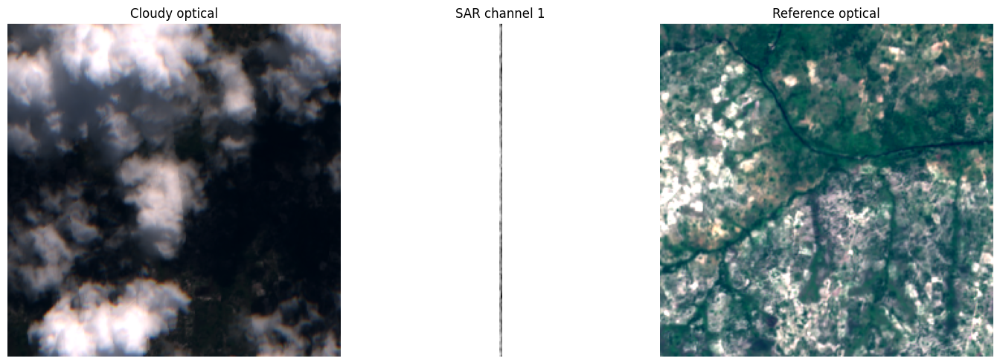

In [ ]:

from datasets import load_dataset
import numpy as np
import matplotlib.pyplot as plt

# Streaming: do not download the entire dataset
ds = load_dataset(
    "Hermanni/sen12mscr",
    split="train",
    streaming=True
)

sample = next(iter(ds))

print("Available fields:", list(sample.keys()))
print("Season:", sample.get("season"))
print("Scene:", sample.get("scene"))
print("Patch:", sample.get("patch"))

sar = np.frombuffer(
    sample["sar"], dtype=np.float32
).reshape(sample["sar_shape"])

cloudy = np.frombuffer(
    sample["cloudy"], dtype=np.int16
).reshape(sample["opt_shape"])

target = np.frombuffer(
    sample["target"], dtype=np.int16
).reshape(sample["opt_shape"])

print("\nArray information")
print("SAR:", sar.shape, sar.dtype)
print("Cloudy optical:", cloudy.shape, cloudy.dtype)
print("Reference optical:", target.shape, target.dtype)

print("\nValue ranges")
print("SAR:", np.nanmin(sar), np.nanmax(sar))
print("Cloudy optical:", cloudy.min(), cloudy.max())
print("Reference optical:", target.min(), target.max())

# Plot a visual preview using bands 4, 3, 2
# (indices 3, 2, 1 for B4, B3, B2)
def show_rgb(image, title):
    rgb = image[:, :, [3, 2, 1]].astype(np.float32)
    lo, hi = np.percentile(rgb, [2, 98])
    rgb = np.clip((rgb - lo) / max(hi - lo, 1e-8), 0, 1)
    plt.imshow(rgb)
    plt.title(title)
    plt.axis("off")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

plt.sca(axes[0])
show_rgb(cloudy, "Cloudy optical")

plt.sca(axes[1])
plt.imshow(sar[0], cmap="gray")
plt.title("SAR channel 1")
plt.axis("off")

plt.sca(axes[2])
show_rgb(target, "Reference optical")

plt.tight_layout()
plt.show()


SAR shape: (256, 256, 2)
SAR dtype: float32
Channel 0: min = -20.313297 max = -3.6385872 mean = -11.134508 std = 2.0056372 unique values = 65253


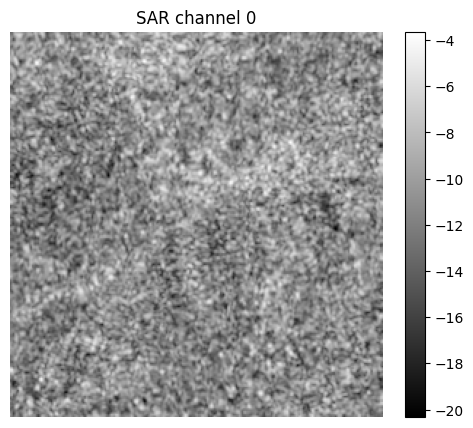

Channel 1: min = -28.220184 max = -9.830634 mean = -16.814486 std = 2.1201417 unique values = 65075


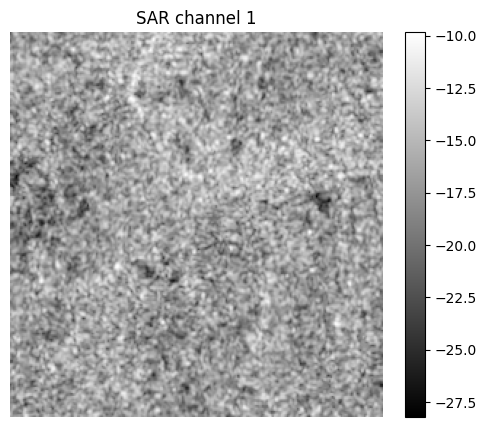

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

print("SAR shape:", sar.shape)
print("SAR dtype:", sar.dtype)

for i in range(sar.shape[-1]):
    channel = sar[..., i]

    print(
        f"Channel {i}:",
        "min =", np.nanmin(channel),
        "max =", np.nanmax(channel),
        "mean =", np.nanmean(channel),
        "std =", np.nanstd(channel),
        "unique values =", np.unique(channel).size
    )

    plt.figure(figsize=(6, 5))
    plt.imshow(channel, cmap="gray", aspect="auto")
    plt.colorbar()
    plt.title(f"SAR channel {i}")
    plt.axis("off")
    plt.show()


/tmp/ipykernel_660/3497761041.py:17: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


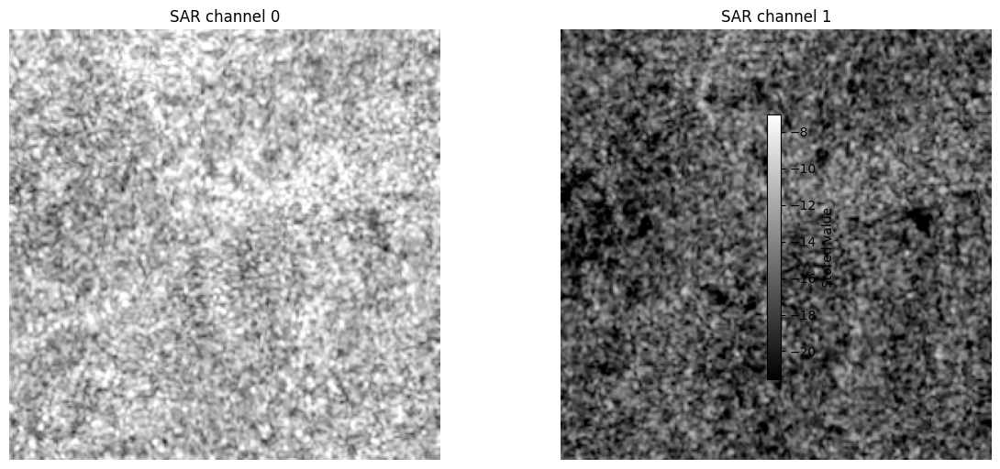

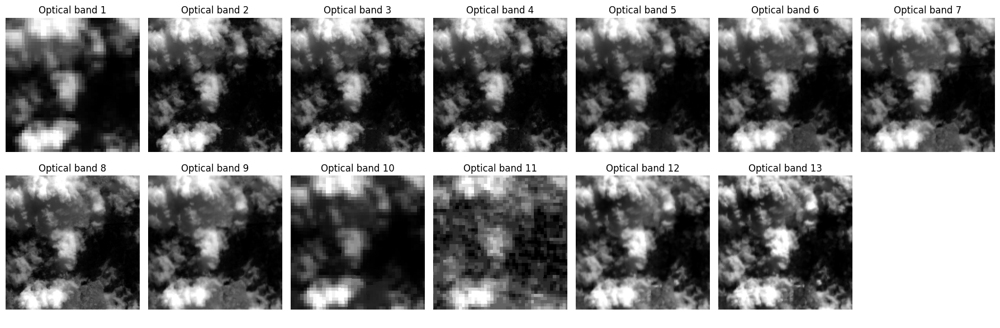

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Use common limits to compare the two SAR channels
vmin = min(np.percentile(sar[..., i], 2) for i in range(2))
vmax = max(np.percentile(sar[..., i], 98) for i in range(2))

for i, ax in enumerate(axes):
    im = ax.imshow(sar[..., i], cmap="gray",
                   vmin=vmin, vmax=vmax)
    ax.set_title(f"SAR channel {i}")
    ax.axis("off")

fig.colorbar(im, ax=axes, shrink=0.75, label="Stored value")
plt.tight_layout()
plt.show()

# Inspect the 13 optical bands
fig, axes = plt.subplots(2, 7, figsize=(18, 6))
axes = axes.flatten()

for i in range(13):
    band = cloudy[..., i]
    lo, hi = np.percentile(band, [2, 98])
    axes[i].imshow(band, cmap="gray", vmin=lo, vmax=hi)
    axes[i].set_title(f"Optical band {i + 1}")
    axes[i].axis("off")

axes[13].axis("off")
plt.tight_layout()
plt.show()


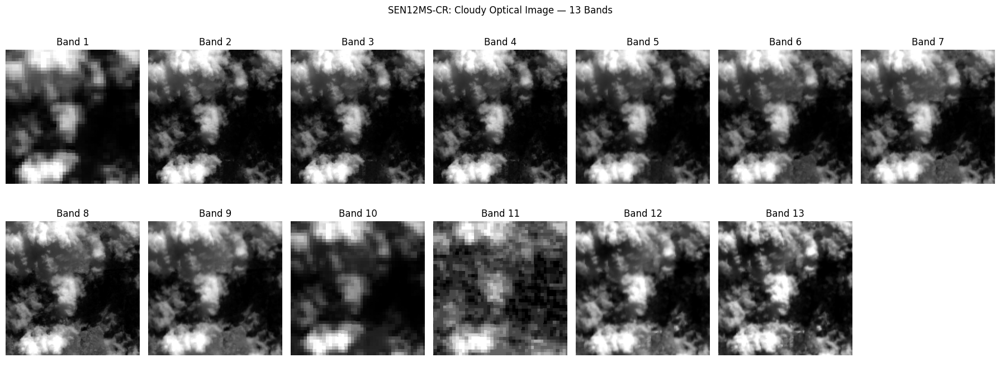

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 7, figsize=(18, 7))
axes = axes.ravel()

for i in range(13):
    band = cloudy[:, :, i].astype(np.float32)

    lo, hi = np.percentile(band, [2, 98])

    axes[i].imshow(
        band,
        cmap="gray",
        vmin=lo,
        vmax=hi
    )
    axes[i].set_title(f"Band {i + 1}")
    axes[i].axis("off")

axes[13].axis("off")

fig.suptitle("SEN12MS-CR: Cloudy Optical Image — 13 Bands")
plt.tight_layout()
plt.show()


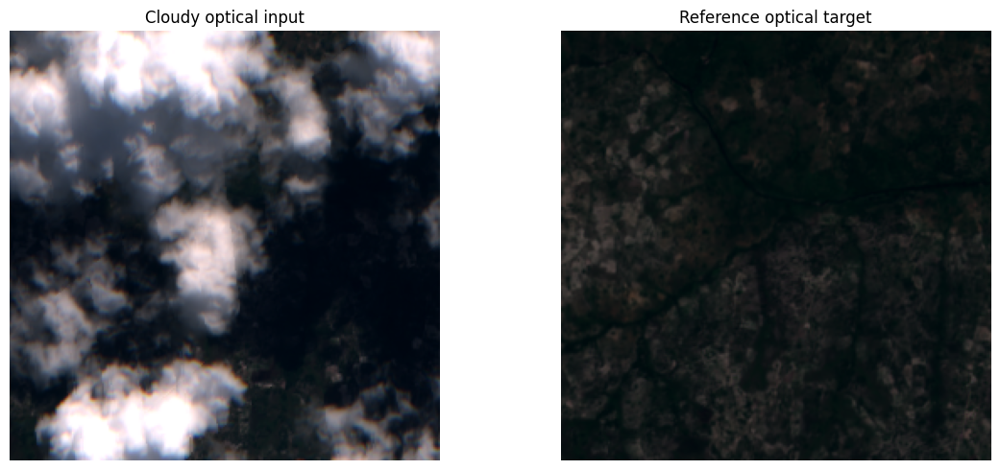

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# Standard Sentinel-2 B4, B3, B2 selection, if the mirror
# preserves the standard band order.
rgb_bands = [3, 2, 1]

cloudy_rgb = cloudy[:, :, rgb_bands].astype(np.float32)
target_rgb = target[:, :, rgb_bands].astype(np.float32)

# Use shared limits so the images are comparable
combined = np.concatenate([
    cloudy_rgb.reshape(-1),
    target_rgb.reshape(-1)
])

lo, hi = np.percentile(combined, [2, 98])

def display_rgb(ax, arr, title):
    arr = np.clip((arr - lo) / max(hi - lo, 1e-8), 0, 1)
    ax.imshow(arr)
    ax.set_title(title)
    ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

display_rgb(axes[0], cloudy_rgb, "Cloudy optical input")
display_rgb(axes[1], target_rgb, "Reference optical target")

plt.tight_layout()
plt.show()


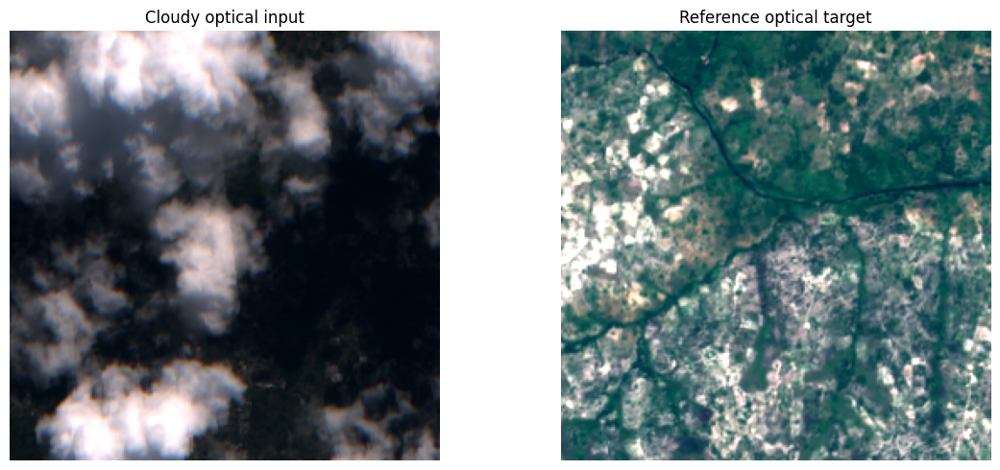

Cloudy optical range: 5 10588
Reference optical range: 7 4955


In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# Assumes standard Sentinel-2 ordering: B4, B3, B2
rgb_bands = [3, 2, 1]

cloudy_rgb = cloudy[:, :, rgb_bands].astype(np.float32)
target_rgb = target[:, :, rgb_bands].astype(np.float32)

def stretch_rgb(img):
    lo, hi = np.percentile(img, [2, 98])
    return np.clip((img - lo) / max(hi - lo, 1e-8), 0, 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(stretch_rgb(cloudy_rgb))
axes[0].set_title("Cloudy optical input")
axes[0].axis("off")

axes[1].imshow(stretch_rgb(target_rgb))
axes[1].set_title("Reference optical target")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Cloudy optical range:", cloudy.min(), cloudy.max())
print("Reference optical range:", target.min(), target.max())


In [ ]:

from datasets import load_dataset
from collections import Counter

# Stream the data; don't download the full dataset
ds = load_dataset(
    "Hermanni/sen12mscr",
    streaming=True
)

for split_name in ds.keys():
    split = ds[split_name]

    print(f"\n{'=' * 40}")
    print("SPLIT:", split_name)
    print("COLUMNS:", split.column_names)

    seasons = Counter()
    scenes = set()
    count = 0

    for sample in split:
        count += 1
        seasons[sample["season"]] += 1
        scenes.add((sample["season"], sample["scene"]))

    print("Total samples:", count)
    print("Number of season/scene combinations:", len(scenes))
    print("Samples by season:")

    for season, n in sorted(seasons.items()):
        print(f"  {season}: {n}")


Resolving data files:   0%|          | 0/155 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/155 [00:00<?, ?it/s]


SPLIT: train
COLUMNS: ['sar', 'cloudy', 'target', 'sar_shape', 'opt_shape', 'dtype', 'season', 'scene', 'patch']


KeyboardInterrupt: 

In [ ]:

from datasets import load_dataset

ds = load_dataset(
    "Hermanni/sen12mscr",
    streaming=True
)

print("Available splits:", list(ds.keys()))

for split_name in ds.keys():
    split = ds[split_name]

    print(f"\n--- {split_name.upper()} ---")
    print("Columns:", split.column_names)

    # Read only ONE sample
    sample = next(iter(split))

    print("Example season:", sample["season"])
    print("Example scene:", sample["scene"])
    print("Example patch:", sample["patch"])
    print("SAR shape:", sample["sar_shape"])
    print("Optical shape:", sample["opt_shape"])


Resolving data files:   0%|          | 0/155 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/155 [00:00<?, ?it/s]

Available splits: ['train', 'validation', 'test']

--- TRAIN ---
Columns: ['sar', 'cloudy', 'target', 'sar_shape', 'opt_shape', 'dtype', 'season', 'scene', 'patch']
Example season: spring
Example scene: 1
Example patch: p100
SAR shape: [256, 256, 2]
Optical shape: [256, 256, 13]

--- VALIDATION ---
Columns: ['sar', 'cloudy', 'target', 'sar_shape', 'opt_shape', 'dtype', 'season', 'scene', 'patch']
Example season: spring
Example scene: 17
Example patch: p100
SAR shape: [256, 256, 2]
Optical shape: [256, 256, 13]

--- TEST ---
Columns: ['sar', 'cloudy', 'target', 'sar_shape', 'opt_shape', 'dtype', 'season', 'scene', 'patch']
Example season: spring
Example scene: 31
Example patch: p100
SAR shape: [256, 256, 2]
Optical shape: [256, 256, 13]


In [ ]:

from huggingface_hub import HfApi

api = HfApi()
repo_id = "Hermanni/sen12mscr"

# List files stored in the dataset repository
files = api.list_repo_files(
    repo_id=repo_id,
    repo_type="dataset"
)

print("Total repository files:", len(files))
print("\nFirst 50 files:")

for file in files[:50]:
    print(file)


Total repository files: 177

First 50 files:
.gitattributes
README.md
fall/scene_1.parquet
fall/scene_100.parquet
fall/scene_104.parquet
fall/scene_105.parquet
fall/scene_107.parquet
fall/scene_109.parquet
fall/scene_11.parquet
fall/scene_110.parquet
fall/scene_112.parquet
fall/scene_114.parquet
fall/scene_116.parquet
fall/scene_119.parquet
fall/scene_120.parquet
fall/scene_122.parquet
fall/scene_125.parquet
fall/scene_128.parquet
fall/scene_131.parquet
fall/scene_133.parquet
fall/scene_134.parquet
fall/scene_135.parquet
fall/scene_136.parquet
fall/scene_139.parquet
fall/scene_14.parquet
fall/scene_141.parquet
fall/scene_142.parquet
fall/scene_144.parquet
fall/scene_147.parquet
fall/scene_148.parquet
fall/scene_149.parquet
fall/scene_19.parquet
fall/scene_22.parquet
fall/scene_26.parquet
fall/scene_27.parquet
fall/scene_28.parquet
fall/scene_3.parquet
fall/scene_30.parquet
fall/scene_31.parquet
fall/scene_33.parquet
fall/scene_35.parquet
fall/scene_37.parquet
fall/scene_39.parquet
fall

In [ ]:

from datasets import load_dataset
from collections import Counter

ds = load_dataset(
    "Hermanni/sen12mscr",
    streaming=True
)

for split_name in ds.keys():
    print(f"\n{'=' * 35}")
    print(f"SPLIT: {split_name.upper()}")
    print("=" * 35)

    season_counts = Counter()
    total = 0

    for sample in ds[split_name]:
        season_counts[sample["season"]] += 1
        total += 1

    print("Total samples:", total)

    for season in ["spring", "summer", "fall", "winter"]:
        print(f"{season.capitalize():<10}: {season_counts[season]:,}")

    print("Total season counts:", sum(season_counts.values()))


Resolving data files:   0%|          | 0/155 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/155 [00:00<?, ?it/s]


SPLIT: TRAIN


KeyboardInterrupt: 

In [ ]:

from datasets import load_dataset
from itertools import islice
from collections import Counter

ds = load_dataset(
    "Hermanni/sen12mscr",
    split="train",
    streaming=True
)

# Read only the first 100 samples
small_part = list(islice(ds, 100))

print("Samples loaded:", len(small_part))
print("Season counts:", Counter(x["season"] for x in small_part))
print("Scenes:", len(set(x["scene"] for x in small_part)))


README.md:   0%|          | 0.00/9.24k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/155 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/155 [00:00<?, ?it/s]

Samples loaded: 100
Season counts: Counter({'spring': 100})
Scenes: 1


In [ ]:
#downloading 200 sample

from datasets import load_dataset
from itertools import islice
from collections import Counter

# Stream the training split
ds = load_dataset(
    "Hermanni/sen12mscr",
    split="train",
    streaming=True
)

# Take only 200 samples
samples = list(islice(ds, 200))

print("TOTAL SAMPLES LOADED:", len(samples))

# Count samples by season
print("\nSamples by season:")
for season, count in sorted(
    Counter(s["season"] for s in samples).items()
):
    print(f"{season}: {count}")

# Count unique scenes
print("\nUnique scenes:", len(set(s["scene"] for s in samples)))

# Show a few sample IDs
print("\nFirst 10 samples:")
for s in samples[:10]:
    print(
        f"Season: {s['season']}, "
        f"Scene: {s['scene']}, "
        f"Patch: {s['patch']}"
    )

# Check the image shapes
print("\nSAR shape:", samples[0]["sar_shape"])
print("Optical shape:", samples[0]["opt_shape"])


Resolving data files:   0%|          | 0/155 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/155 [00:00<?, ?it/s]

TOTAL SAMPLES LOADED: 200

Samples by season:
spring: 200

Unique scenes: 1

First 10 samples:
Season: spring, Scene: 1, Patch: p100
Season: spring, Scene: 1, Patch: p101
Season: spring, Scene: 1, Patch: p102
Season: spring, Scene: 1, Patch: p103
Season: spring, Scene: 1, Patch: p104
Season: spring, Scene: 1, Patch: p105
Season: spring, Scene: 1, Patch: p106
Season: spring, Scene: 1, Patch: p107
Season: spring, Scene: 1, Patch: p108
Season: spring, Scene: 1, Patch: p109

SAR shape: [256, 256, 2]
Optical shape: [256, 256, 13]


In [ ]:

from datasets import load_dataset
from itertools import islice
from pathlib import Path
import numpy as np
import pandas as pd
import zipfile

# Folder for our small dataset
out_dir = Path("/content/sen12mscr_200")
out_dir.mkdir(parents=True, exist_ok=True)

# Stream the training split
ds = load_dataset(
    "Hermanni/sen12mscr",
    split="train",
    streaming=True
)

metadata = []

for i, sample in enumerate(islice(ds, 200)):
    # Decode the arrays
    sar = np.frombuffer(
        sample["sar"], dtype=np.float32
    ).reshape(sample["sar_shape"])

    cloudy = np.frombuffer(
        sample["cloudy"], dtype=np.int16
    ).reshape(sample["opt_shape"])

    target = np.frombuffer(
        sample["target"], dtype=np.int16
    ).reshape(sample["opt_shape"])

    # Save all three arrays in one compressed file
    np.savez_compressed(
        out_dir / f"sample_{i:03d}.npz",
        sar=sar,
        cloudy=cloudy,
        target=target
    )

    metadata.append({
        "sample_id": i,
        "season": sample["season"],
        "scene": sample["scene"],
        "patch": sample["patch"]
    })

    if (i + 1) % 25 == 0:
        print(f"Saved {i + 1}/200 samples")

# Save metadata
pd.DataFrame(metadata).to_csv(
    out_dir / "metadata.csv", index=False
)

print("\nTotal samples saved:", len(metadata))
print("Saved to:", out_dir)


Resolving data files:   0%|          | 0/155 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/155 [00:00<?, ?it/s]

Saved 25/200 samples
Saved 50/200 samples
Saved 75/200 samples
Saved 100/200 samples
Saved 125/200 samples
Saved 150/200 samples
Saved 175/200 samples
Saved 200/200 samples

Total samples saved: 200
Saved to: /content/sen12mscr_200


In [ ]:

import shutil

zip_path = shutil.make_archive(
    "/content/sen12mscr_200",
    "zip",
    root_dir="/content",
    base_dir="sen12mscr_200"
)

print("ZIP created:", zip_path)


ZIP created: /content/sen12mscr_200.zip


In [ ]:

from google.colab import files

files.download("/content/sen12mscr_200.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

In [ ]:

from google.colab import files
uploaded = files.upload()


Saving sen12mscr_200.zip to sen12mscr_200 (1).zip


In [ ]:

import zipfile
from pathlib import Path

# The filename shown in your screenshot
zip_path = "/content/sen12mscr_200 (1).zip"
extract_dir = Path("/content/sen12mscr_extracted")

extract_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

print("Extraction complete!")

npz_files = list(extract_dir.rglob("sample_*.npz"))
print("Total NPZ samples found:", len(npz_files))
print("First few files:")
for f in npz_files[:5]:
    print(f.name)


Extraction complete!
Total NPZ samples found: 200
First few files:
sample_069.npz
sample_158.npz
sample_106.npz
sample_135.npz
sample_138.npz


In [ ]:

import numpy as np
from PIL import Image

output_dir = extract_dir / "jpg_images"
output_dir.mkdir(exist_ok=True)

def optical_to_jpg(array, path):
    rgb = array[:, :, [3, 2, 1]].astype(np.float32)
    lo, hi = np.percentile(rgb, [2, 98])
    rgb = np.clip((rgb - lo) / (hi - lo + 1e-8), 0, 1)
    Image.fromarray((rgb * 255).astype(np.uint8)).save(path, quality=95)

def sar_to_jpg(array, path):
    lo, hi = np.percentile(array, [2, 98])
    scaled = np.clip((array - lo) / (hi - lo + 1e-8), 0, 1)
    Image.fromarray((scaled * 255).astype(np.uint8)).save(path, quality=95)

for i, f in enumerate(npz_files, start=1):
    with np.load(f) as data:
        optical_to_jpg(data["cloudy"], output_dir / f"{f.stem}_cloudy.jpg")
        optical_to_jpg(data["target"], output_dir / f"{f.stem}_target.jpg")
        sar_to_jpg(data["sar"][:, :, 0], output_dir / f"{f.stem}_sar.jpg")

    if i % 25 == 0:
        print(f"Converted {i}/{len(npz_files)} samples")

print("JPG images saved in:", output_dir)


Converted 25/200 samples
Converted 50/200 samples
Converted 75/200 samples
Converted 100/200 samples
Converted 125/200 samples
Converted 150/200 samples
Converted 175/200 samples
Converted 200/200 samples
JPG images saved in: /content/sen12mscr_extracted/jpg_images


Cloudy images found: 200


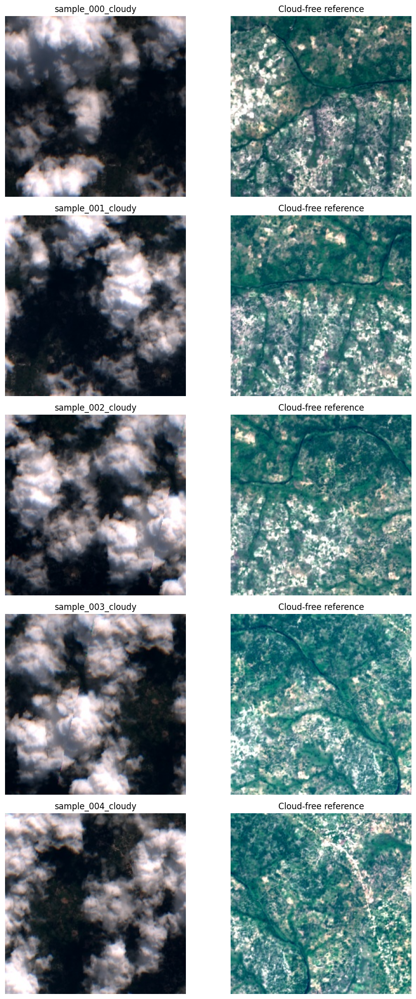

In [ ]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

output_dir = Path("/content/sen12mscr_extracted/jpg_images")

# Find the first cloudy and target images
cloudy_files = sorted(output_dir.glob("*_cloudy.jpg"))

print("Cloudy images found:", len(cloudy_files))

# Display 5 examples
fig, axes = plt.subplots(5, 2, figsize=(10, 20))

for i, cloudy_file in enumerate(cloudy_files[:5]):
    target_file = output_dir / cloudy_file.name.replace(
        "_cloudy.jpg", "_target.jpg"
    )

    axes[i, 0].imshow(Image.open(cloudy_file))
    axes[i, 0].set_title(cloudy_file.stem)
    axes[i, 0].axis("off")

    axes[i, 1].imshow(Image.open(target_file))
    axes[i, 1].set_title("Cloud-free reference")
    axes[i, 1].axis("off")

axes[0, 0].set_ylabel("CLOUDY", fontsize=12)
axes[0, 1].set_ylabel("TARGET", fontsize=12)

plt.tight_layout()
plt.show()


In [ ]:

import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/sen12mscr_200_jpgs",
    "zip",
    root_dir="/content/sen12mscr_extracted",
    base_dir="jpg_images"
)

files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:

from pathlib import Path

# Check common locations
for folder in ["/content", "/content/sen12mscr_extracted",
               "/content/sen12mscr_200"]:
    p = Path(folder)
    print(f"\n{folder} exists: {p.exists()}")

    if p.exists():
        files = list(p.rglob("sample_*.npz"))
        print("NPZ files found:", len(files))
        if files:
            print("Example:", files[0])



/content exists: True
NPZ files found: 0

/content/sen12mscr_extracted exists: False

/content/sen12mscr_200 exists: False


In [6]:

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

# Your Drive folder from the screenshot
drive_folder = Path('/content/drive/MyDrive/DL/Dataset')

print("Folder exists:", drive_folder.exists())

if drive_folder.exists():
    for item in drive_folder.iterdir():
        print(item.name)


Mounted at /content/drive
Folder exists: True
jpg_images
Untitled0.ipynb


In [7]:

from pathlib import Path

drive_folder = Path("/content/drive/MyDrive/DL/Dataset")
jpg_folder = drive_folder / "jpg_images"

print("JPG folder exists:", jpg_folder.exists())

if jpg_folder.exists():
    jpg_files = list(jpg_folder.glob("*.jpg"))
    print("Total JPG images:", len(jpg_files))
    print("\nFirst 10 images:")
    for f in sorted(jpg_files)[:10]:
        print(f.name)

# Check for original NPZ files anywhere under Dataset
npz_files = list(drive_folder.rglob("*.npz"))
print("\nOriginal NPZ files found:", len(npz_files))


JPG folder exists: True
Total JPG images: 600

First 10 images:
sample_000_cloudy.jpg
sample_000_sar.jpg
sample_000_target.jpg
sample_001_cloudy.jpg
sample_001_sar.jpg
sample_001_target.jpg
sample_002_cloudy.jpg
sample_002_sar.jpg
sample_002_target.jpg
sample_003_cloudy.jpg

Original NPZ files found: 0


In [8]:

from pathlib import Path

drive_folder = Path("/content/drive/MyDrive/DL/Dataset")

zip_files = list(drive_folder.rglob("*.zip"))
npz_files = list(drive_folder.rglob("*.npz"))

print("ZIP files found:", len(zip_files))
for f in zip_files:
    print(f, f.stat().st_size / (1024**2), "MB")

print("\nNPZ files found:", len(npz_files))


ZIP files found: 0

NPZ files found: 0


In [9]:

from pathlib import Path

# Connect to your Google Drive folder
drive_folder = Path("/content/drive/MyDrive/sen12mscr_200/sen12mscr_200")

npz_files = sorted(drive_folder.glob("sample_*.npz"))

print("Total NPZ samples:", len(npz_files))
print("First 5 files:")

for f in npz_files[:5]:
    print(f.name, "-", round(f.stat().st_size / (1024**2), 2), "MB")


Total NPZ samples: 0
First 5 files:


In [10]:

from pathlib import Path

drive_root = Path("/content/drive/MyDrive")

print("Drive mounted:", drive_root.exists())

# Find the dataset folder and sample files
matches = list(drive_root.rglob("sample_000.npz"))

print("Locations containing sample_000.npz:", len(matches))

for f in matches[:10]:
    print("\nFound:", f)
    print("Parent folder:", f.parent)


Drive mounted: True
Locations containing sample_000.npz: 1

Found: /content/drive/MyDrive/DL/Dataset/sen12mscr_200/sen12mscr_200/sample_000.npz
Parent folder: /content/drive/MyDrive/DL/Dataset/sen12mscr_200/sen12mscr_200


In [11]:

from pathlib import Path
import numpy as np

drive_folder = Path(
    "/content/drive/MyDrive/DL/Dataset/sen12mscr_200/sen12mscr_200"
)

npz_files = sorted(drive_folder.glob("sample_*.npz"))

print("=" * 45)
print("SEN12MS-CR DATASET AUDIT")
print("=" * 45)
print("Total NPZ samples:", len(npz_files))

if not npz_files:
    raise FileNotFoundError("No NPZ samples found in the folder.")

# Inspect the first sample
with np.load(npz_files[0]) as data:
    print("\nSample:", npz_files[0].name)
    print("Available arrays:", data.files)

    for key in ["sar", "cloudy", "target"]:
        arr = data[key]
        print(f"\n{key.upper()}")
        print("Shape:", arr.shape)
        print("Data type:", arr.dtype)
        print("Minimum:", arr.min())
        print("Maximum:", arr.max())
        print("Mean:", arr.mean())
        print("NaN values:", np.isnan(arr).sum())
        print("Infinite values:", np.isinf(arr).sum())


SEN12MS-CR DATASET AUDIT
Total NPZ samples: 201

Sample: sample_000.npz
Available arrays: ['sar', 'cloudy', 'target']

SAR
Shape: (256, 256, 2)
Data type: float32
Minimum: -28.220184
Maximum: -3.6385872
Mean: -13.974496
NaN values: 0
Infinite values: 0

CLOUDY
Shape: (256, 256, 13)
Data type: int16
Minimum: 5
Maximum: 10588
Mean: 2545.270476121169
NaN values: 0
Infinite values: 0

TARGET
Shape: (256, 256, 13)
Data type: int16
Minimum: 7
Maximum: 4955
Mean: 1664.854508620042
NaN values: 0
Infinite values: 0


In [12]:

required = {"sar", "cloudy", "target"}
valid = 0
problems = []

for f in npz_files:
    try:
        with np.load(f) as data:
            if not required.issubset(data.files):
                problems.append((f.name, "Missing required arrays"))
                continue

            sar = data["sar"]
            cloudy = data["cloudy"]
            target = data["target"]

            if (sar.shape != (256, 256, 2)
                or cloudy.shape != (256, 256, 13)
                or target.shape != (256, 256, 13)):
                problems.append(
                    (f.name, f"Unexpected shapes: {sar.shape}, "
                     f"{cloudy.shape}, {target.shape}")
                )
                continue

            if not all(
                np.isfinite(a).all()
                for a in [sar, cloudy, target]
            ):
                problems.append((f.name, "NaN or infinite values"))
                continue

            valid += 1

    except Exception as e:
        problems.append((f.name, str(e)))

print("Total files:", len(npz_files))
print("Samples passing basic checks:", valid)
print("Samples with problems:", len(problems))

for problem in problems[:20]:
    print(problem)


Total files: 201
Samples passing basic checks: 201
Samples with problems: 0


In [13]:

import numpy as np
from pathlib import Path

# Folder containing your original samples
data_folder = Path(
    "/content/drive/MyDrive/DL/Dataset/sen12mscr_200/sen12mscr_200"
)

# Find all sample files
npz_files = sorted(data_folder.glob("sample_*.npz"))

print("Total sample files:", len(npz_files))

# Open only the first sample
sample_path = npz_files[0]

with np.load(sample_path) as data:
    print("\nFile name:", sample_path.name)
    print("Arrays inside the file:", data.files)

    for name in ["sar", "cloudy", "target"]:
        arr = data[name]

        print(f"\n--- {name.upper()} ---")
        print("Shape:", arr.shape)
        print("Data type:", arr.dtype)
        print("Minimum value:", arr.min())
        print("Maximum value:", arr.max())
        print("Mean value:", arr.mean())


Total sample files: 201

File name: sample_000.npz
Arrays inside the file: ['sar', 'cloudy', 'target']

--- SAR ---
Shape: (256, 256, 2)
Data type: float32
Minimum value: -28.220184
Maximum value: -3.6385872
Mean value: -13.974496

--- CLOUDY ---
Shape: (256, 256, 13)
Data type: int16
Minimum value: 5
Maximum value: 10588
Mean value: 2545.270476121169

--- TARGET ---
Shape: (256, 256, 13)
Data type: int16
Minimum value: 7
Maximum value: 4955
Mean value: 1664.854508620042


In [14]:

import numpy as np
from pathlib import Path

data_folder = Path(
    "/content/drive/MyDrive/DL/Dataset/sen12mscr_200/sen12mscr_200"
)

npz_files = sorted(data_folder.glob("sample_*.npz"))

print("Total files:", len(npz_files))

# Track overall ranges and sample problems
stats = {
    "sar": {"min": float("inf"), "max": float("-inf")},
    "cloudy": {"min": float("inf"), "max": float("-inf")},
    "target": {"min": float("inf"), "max": float("-inf")}
}

problems = []

for i, file_path in enumerate(npz_files):
    try:
        with np.load(file_path) as data:
            for name in ["sar", "cloudy", "target"]:
                arr = data[name]

                if not np.isfinite(arr).all():
                    problems.append((file_path.name, name, "Invalid values"))
                    continue

                stats[name]["min"] = min(
                    stats[name]["min"], float(arr.min())
                )
                stats[name]["max"] = max(
                    stats[name]["max"], float(arr.max())
                )

    except Exception as e:
        problems.append((file_path.name, "file", str(e)))

    if (i + 1) % 50 == 0:
        print(f"Checked {i + 1}/{len(npz_files)} files")

print("\n--- OVERALL VALUE RANGES ---")
for name, values in stats.items():
    print(f"{name.upper()}: min={values['min']:.3f}, "
          f"max={values['max']:.3f}")

print("\nFiles with reading or numerical problems:", len(problems))
for problem in problems[:10]:
    print(problem)


Total files: 201
Checked 50/201 files
Checked 100/201 files
Checked 150/201 files
Checked 200/201 files

--- OVERALL VALUE RANGES ---
SAR: min=-33.525, max=0.000
CLOUDY: min=3.000, max=14482.000
TARGET: min=4.000, max=11569.000

Files with reading or numerical problems: 0


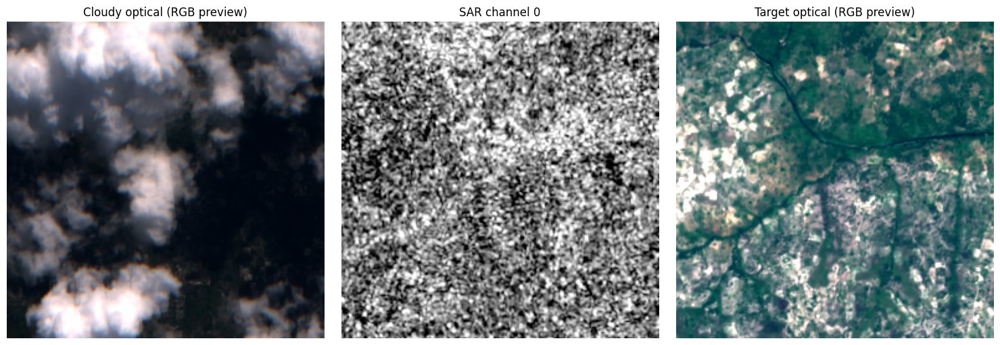

In [15]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

data_folder = Path(
    "/content/drive/MyDrive/DL/Dataset/sen12mscr_200/sen12mscr_200"
)

sample_path = data_folder / "sample_000.npz"

with np.load(sample_path) as data:
    cloudy = data["cloudy"].astype(np.float32)
    target = data["target"].astype(np.float32)
    sar = data["sar"].astype(np.float32)

def make_rgb(image):
    # Candidate natural-colour display:
    # assumes band indices [3, 2, 1] correspond to B4, B3, B2
    rgb = image[:, :, [3, 2, 1]]
    lo, hi = np.percentile(rgb, [2, 98])
    return np.clip((rgb - lo) / (hi - lo + 1e-8), 0, 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(make_rgb(cloudy))
axes[0].set_title("Cloudy optical (RGB preview)")

sar_channel = sar[:, :, 0]
lo, hi = np.percentile(sar_channel, [2, 98])
axes[1].imshow(sar_channel, cmap="gray", vmin=lo, vmax=hi)
axes[1].set_title("SAR channel 0")

axes[2].imshow(make_rgb(target))
axes[2].set_title("Target optical (RGB preview)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [16]:
from pathlib import Path
import pandas as pd
import numpy as np

data_folder = Path(
    "/content/drive/MyDrive/DL/Dataset/sen12mscr_200/sen12mscr_200"
)

# 1. Inspect the metadata file
metadata_path = data_folder / "metadata.csv"

if metadata_path.exists():
    metadata = pd.read_csv(metadata_path)
    print("METADATA COLUMNS:")
    print(metadata.columns.tolist())

    print("\nFIRST 5 METADATA ROWS:")
    display(metadata.head())
else:
    print("metadata.csv not found at:", metadata_path)

# 2. Inspect the array keys and shapes
sample_path = data_folder / "sample_000.npz"

with np.load(sample_path) as data:
    print("\nARRAY INFORMATION:")
    for key in data.files:
        arr = data[key]
        print(
            f"{key}: shape={arr.shape}, "
            f"dtype={arr.dtype}, "
            f"min={arr.min()}, max={arr.max()}"
        )

METADATA COLUMNS:
['sample_id', 'season', 'scene', 'patch']

FIRST 5 METADATA ROWS:


,sample_id,season,scene,patch
0,0,spring,1,p100
1,1,spring,1,p101
2,2,spring,1,p102
3,3,spring,1,p103
4,4,spring,1,p104



ARRAY INFORMATION:
sar: shape=(256, 256, 2), dtype=float32, min=-28.220184326171875, max=-3.638587236404419
cloudy: shape=(256, 256, 13), dtype=int16, min=5, max=10588
target: shape=(256, 256, 13), dtype=int16, min=7, max=4955


In [17]:

from pathlib import Path

data_folder = Path(
    "/content/drive/MyDrive/DL/Dataset/sen12mscr_200/sen12mscr_200"
)

print("Files in dataset folder:")
for path in sorted(data_folder.iterdir()):
    print(path.name)

print("\nSearching nearby folders for documentation/config files:")
root = Path("/content/drive/MyDrive/DL/Dataset")

for path in root.rglob("*"):
    if path.is_file() and path.suffix.lower() in {
        ".json", ".yaml", ".yml", ".txt", ".md"
    }:
        if any(word in path.name.lower()
               for word in ["readme", "config", "band", "sen12", "metadata"]):
            print(path)


Files in dataset folder:
metadata.csv
sample_000.npz
sample_001.npz
sample_002.npz
sample_003.npz
sample_004.npz
sample_005.npz
sample_006.npz
sample_007.npz
sample_008.npz
sample_009.npz
sample_010.npz
sample_011.npz
sample_012.npz
sample_013.npz
sample_014.npz
sample_015.npz
sample_016.npz
sample_017.npz
sample_018.npz
sample_019.npz
sample_020.npz
sample_021.npz
sample_022.npz
sample_023.npz
sample_024.npz
sample_025.npz
sample_026.npz
sample_027.npz
sample_028.npz
sample_029.npz
sample_030.npz
sample_031.npz
sample_032.npz
sample_033.npz
sample_034.npz
sample_035.npz
sample_036.npz
sample_037.npz
sample_038.npz
sample_039.npz
sample_040.npz
sample_041.npz
sample_042.npz
sample_043.npz
sample_044.npz
sample_045.npz
sample_046.npz
sample_047.npz
sample_048.npz
sample_049.npz
sample_050.npz
sample_051.npz
sample_052.npz
sample_053.npz
sample_054.npz
sample_055.npz
sample_056.npz
sample_057.npz
sample_058.npz
sample_059.npz
sample_060.npz
sample_061.npz
sample_062.npz
sample_063.npz
sa

In [19]:
from pathlib import Path
import numpy as np

data_folder = Path(
    "/content/drive/MyDrive/DL/Dataset/sen12mscr_200/sen12mscr_200"
)

original = data_folder / "sample_066.npz"
duplicate = data_folder / "sample_066 (1).npz"

print("Numbered samples (000–199):",
      sum((data_folder / f"sample_{i:03d}.npz").exists()
          for i in range(200)))

print("\nDuplicate file exists:", duplicate.exists())

if original.exists() and duplicate.exists():
    with np.load(original) as a, np.load(duplicate) as b:
        print("\nArray keys match:", a.files == b.files)

        for key in a.files:
            same = (
                key in b.files
                and a[key].shape == b[key].shape
                and np.array_equal(a[key], b[key])
            )
            print(f"{key}: identical =", same)

    print("\nOriginal size (MB):",
          round(original.stat().st_size / (1024**2), 2))
    print("Duplicate size (MB):",
          round(duplicate.stat().st_size / (1024**2), 2))

Numbered samples (000–199): 200

Duplicate file exists: True

Array keys match: True
sar: identical = True
cloudy: identical = True
target: identical = True

Original size (MB): 2.4
Duplicate size (MB): 2.4


In [20]:
from pathlib import Path
import numpy as np

data_folder = Path(
    "/content/drive/MyDrive/DL/Dataset/sen12mscr_200/sen12mscr_200"
)

original = data_folder / "sample_066.npz"
duplicate = data_folder / "sample_066 (1).npz"

if not original.exists() or not duplicate.exists():
    print("One or both files are missing. Nothing deleted.")

else:
    with np.load(original) as a, np.load(duplicate) as b:
        identical = (
            a.files == b.files
            and all(
                key in b.files
                and np.array_equal(a[key], b[key])
                for key in a.files
            )
        )

    if identical:
        duplicate.unlink()
        print("Verified duplicate removed successfully.")
    else:
        print("Files differ. Nothing deleted.")

print(
    "Remaining numbered samples:",
    len(list(data_folder.glob("sample_[0-9][0-9][0-9].npz")))
)

Verified duplicate removed successfully.
Remaining numbered samples: 200


In [21]:

import numpy as np
from pathlib import Path

data_folder = Path(
    "/content/drive/MyDrive/DL/Dataset/sen12mscr_200/sen12mscr_200"
)

with np.load(data_folder / "sample_000.npz") as d:
    for name in ["cloudy", "target"]:
        arr = d[name].astype(np.float32) / 10000.0
        print(f"{name}:")
        print("  min:", arr.min())
        print("  max:", arr.max())
        print("  mean:", arr.mean())
        print("  finite values:", np.isfinite(arr).all())


cloudy:
  min: 0.0005
  max: 1.0588
  mean: 0.25452703
  finite values: True
target:
  min: 0.0007
  max: 0.4955
  mean: 0.16648546
  finite values: True


In [22]:

from pathlib import Path
import numpy as np

data_folder = Path(
    "/content/drive/MyDrive/DL/Dataset/sen12mscr_200/sen12mscr_200"
)

files = sorted(data_folder.glob("sample_[0-9][0-9][0-9].npz"))

expected_shapes = {
    "sar": (256, 256, 2),
    "cloudy": (256, 256, 13),
    "target": (256, 256, 13),
}

problems = []
global_ranges = {
    key: [float("inf"), float("-inf")]
    for key in expected_shapes
}

for path in files:
    try:
        with np.load(path) as sample:
            for key, expected_shape in expected_shapes.items():
                arr = sample[key]

                if arr.shape != expected_shape:
                    problems.append(
                        f"{path.name}: {key} shape {arr.shape}"
                    )

                if not np.isfinite(arr).all():
                    problems.append(
                        f"{path.name}: {key} contains NaN/Inf"
                    )
                else:
                    global_ranges[key][0] = min(
                        global_ranges[key][0], float(arr.min())
                    )
                    global_ranges[key][1] = max(
                        global_ranges[key][1], float(arr.max())
                    )

    except Exception as e:
        problems.append(f"{path.name}: {e}")

print("Samples checked:", len(files))
print("Problems found:", len(problems))

for key, (minimum, maximum) in global_ranges.items():
    print(f"{key}: overall min={minimum:.5f}, max={maximum:.5f}")

if problems:
    print("\nFirst 10 problems:")
    print(*problems[:10], sep="\n")
else:
    print("All samples passed the checks!")


Samples checked: 200
Problems found: 0
sar: overall min=-33.52450, max=0.00000
cloudy: overall min=3.00000, max=14482.00000
target: overall min=4.00000, max=11569.00000
All samples passed the checks!


In [23]:

from pathlib import Path
import numpy as np

data_folder = Path(
    "/content/drive/MyDrive/DL/Dataset/sen12mscr_200/sen12mscr_200"
)

files = sorted(data_folder.glob("sample_[0-9][0-9][0-9].npz"))

sar_values = []

for path in files:
    with np.load(path) as sample:
        sar_values.append(sample["sar"].astype(np.float32))

sar = np.stack(sar_values, axis=0)

print("SAR shape (samples, height, width, channels):", sar.shape)

for channel in range(sar.shape[-1]):
    values = sar[..., channel]
    print(f"\nSAR channel {channel}:")
    print("  Min:", float(values.min()))
    print("  Max:", float(values.max()))
    print("  Mean:", float(values.mean()))
    print("  Std:", float(values.std()))
    print("  Percentiles [1, 25, 50, 75, 99]:",
          np.percentile(values, [1, 25, 50, 75, 99]).round(3))


SAR shape (samples, height, width, channels): (200, 256, 256, 2)

SAR channel 0:
  Min: -27.35427474975586
  Max: 0.0
  Mean: -10.755374908447266
  Std: 2.0208513736724854
  Percentiles [1, 25, 50, 75, 99]: [-15.599 -12.076 -10.728  -9.401  -6.144]

SAR channel 1:
  Min: -33.52450180053711
  Max: -7.20074987411499
  Mean: -16.6361141204834
  Std: 2.0886316299438477
  Percentiles [1, 25, 50, 75, 99]: [-21.96  -17.964 -16.553 -15.211 -12.111]


In [24]:

from pathlib import Path
import numpy as np

data_folder = Path(
    "/content/drive/MyDrive/DL/Dataset/sen12mscr_200/sen12mscr_200"
)

files = sorted(data_folder.glob("sample_[0-9][0-9][0-9].npz"))

cloudy_all = []
target_all = []

for path in files:
    with np.load(path) as sample:
        cloudy_all.append(sample["cloudy"].astype(np.float32))
        target_all.append(sample["target"].astype(np.float32))

cloudy_all = np.stack(cloudy_all) / 10000.0
target_all = np.stack(target_all) / 10000.0

print("Optical shape:", cloudy_all.shape)

print("\nBand-wise statistics after dividing by 10000:")
print("Band | Cloudy mean | Target mean | Cloudy min | Cloudy max")

for band in range(13):
    c = cloudy_all[..., band]
    t = target_all[..., band]

    print(
        f"{band:4d} | {c.mean():11.4f} | {t.mean():11.4f} "
        f"| {c.min():10.4f} | {c.max():10.4f}"
    )

print("\nAll cloudy values finite:", np.isfinite(cloudy_all).all())
print("All target values finite:", np.isfinite(target_all).all())


Optical shape: (200, 256, 256, 13)

Band-wise statistics after dividing by 10000:
Band | Cloudy mean | Target mean | Cloudy min | Cloudy max
   0 |      0.2638 |      0.1344 |     0.1187 |     1.0829
   1 |      0.2381 |      0.1122 |     0.0826 |     1.1986
   2 |      0.2217 |      0.1140 |     0.0531 |     1.2131
   3 |      0.2190 |      0.1016 |     0.0295 |     1.3507
   4 |      0.2381 |      0.1375 |     0.0294 |     1.3453
   5 |      0.3098 |      0.2488 |     0.0290 |     1.3858
   6 |      0.3484 |      0.3003 |     0.0294 |     1.4272
   7 |      0.3290 |      0.2809 |     0.0234 |     1.3759
   8 |      0.3782 |      0.3415 |     0.0239 |     1.4482
   9 |      0.0803 |      0.0340 |     0.0091 |     0.5505
  10 |      0.0014 |      0.0012 |     0.0003 |     0.0044
  11 |      0.2753 |      0.2749 |     0.0113 |     0.8510
  12 |      0.1770 |      0.1593 |     0.0054 |     0.6593

All cloudy values finite: True
All target values finite: True


In [25]:

from pathlib import Path

cache = Path("/root/.cache/huggingface/datasets")

print("Checking Hugging Face cache:", cache)
print("Cache exists:", cache.exists())

if cache.exists():
    matches = [
        p for p in cache.iterdir()
        if "sen12mscr" in p.name.lower()
    ]
    print("\nMatching dataset cache entries:")
    for p in matches:
        print(p.name)
else:
    print("No local Hugging Face dataset cache found.")


Checking Hugging Face cache: /root/.cache/huggingface/datasets
Cache exists: False
No local Hugging Face dataset cache found.


In [26]:
from pathlib import Path
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

data_folder = Path(
    "/content/drive/MyDrive/DL/Dataset/sen12mscr_200/sen12mscr_200"
)

class SEN12MSCRDataset(Dataset):
    def __init__(self, folder):
        self.files = sorted(
            folder.glob("sample_[0-9][0-9][0-9].npz")
        )

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        with np.load(self.files[idx]) as sample:
            sar = sample["sar"].astype(np.float32)
            cloudy = sample["cloudy"].astype(np.float32) / 10000.0
            target = sample["target"].astype(np.float32) / 10000.0

        # HWC -> CHW for PyTorch
        sar = np.transpose(sar, (2, 0, 1)).copy()
        cloudy = np.transpose(cloudy, (2, 0, 1)).copy()
        target = np.transpose(target, (2, 0, 1)).copy()

        return {
            "sar": torch.from_numpy(sar),
            "cloudy": torch.from_numpy(cloudy),
            "target": torch.from_numpy(target),
        }

dataset = SEN12MSCRDataset(data_folder)
loader = DataLoader(dataset, batch_size=4, shuffle=True, num_workers=0)

batch = next(iter(loader))

print("Dataset samples:", len(dataset))
for key, tensor in batch.items():
    print(
        f"{key}: shape={tuple(tensor.shape)}, "
        f"dtype={tensor.dtype}, "
        f"finite={torch.isfinite(tensor).all().item()}"
    )

Dataset samples: 200
sar: shape=(4, 2, 256, 256), dtype=torch.float32, finite=True
cloudy: shape=(4, 13, 256, 256), dtype=torch.float32, finite=True
target: shape=(4, 13, 256, 256), dtype=torch.float32, finite=True


In [27]:

from pathlib import Path
import pandas as pd

data_folder = Path(
    "/content/drive/MyDrive/DL/Dataset/sen12mscr_200/sen12mscr_200"
)

metadata = pd.read_csv(data_folder / "metadata.csv")

print("Metadata rows:", len(metadata))
print("\nColumns:", metadata.columns.tolist())

for column in ["season", "scene", "patch"]:
    if column in metadata.columns:
        print(f"\nUnique {column} values:", metadata[column].nunique())
        print(metadata[column].value_counts().head(10))

if "scene" in metadata.columns:
    print("\nSamples per scene:")
    print(metadata.groupby("scene").size().sort_values(ascending=False))


Metadata rows: 200

Columns: ['sample_id', 'season', 'scene', 'patch']

Unique season values: 1
season
spring    200
Name: count, dtype: int64

Unique scene values: 1
scene
1    200
Name: count, dtype: int64

Unique patch values: 200
patch
p100    1
p101    1
p102    1
p103    1
p104    1
p105    1
p106    1
p107    1
p108    1
p109    1
Name: count, dtype: int64

Samples per scene:
scene
1    200
dtype: int64


In [28]:

from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

data_folder = Path(
    "/content/drive/MyDrive/DL/Dataset/sen12mscr_200/sen12mscr_200"
)

metadata = pd.read_csv(data_folder / "metadata.csv")

train_df, val_df = train_test_split(
    metadata,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

train_ids = set(train_df["sample_id"].astype(str))
val_ids = set(val_df["sample_id"].astype(str))

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Overlap:", len(train_ids & val_ids))

print("\nTraining preview:")
print(train_df.head())

print("\nValidation preview:")
print(val_df.head())

split_path = data_folder / "train_val_split.csv"

split_df = metadata[["sample_id"]].copy()
split_df["split"] = split_df["sample_id"].astype(str).map(
    lambda x: "train" if x in train_ids else "validation"
)
split_df.to_csv(split_path, index=False)

print("\nSplit saved to:", split_path)


Training samples: 160
Validation samples: 40
Overlap: 0

Training preview:
     sample_id  season  scene patch
79          79  spring      1  p182
197        197  spring      1  p303
38          38  spring      1  p139
24          24  spring      1  p125
122        122  spring      1  p226

Validation preview:
     sample_id  season  scene patch
95          95  spring      1  p198
15          15  spring      1  p115
30          30  spring      1  p131
158        158  spring      1  p264
128        128  spring      1  p233

Split saved to: /content/drive/MyDrive/DL/Dataset/sen12mscr_200/sen12mscr_200/train_val_split.csv


In [29]:

import torch
import torch.nn as nn

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNetBaseline(nn.Module):
    def __init__(self, in_channels=15, out_channels=13):
        super().__init__()

        self.enc1 = ConvBlock(in_channels, 32)
        self.enc2 = ConvBlock(32, 64)
        self.enc3 = ConvBlock(64, 128)

        self.pool = nn.MaxPool2d(2)
        self.bottleneck = ConvBlock(128, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = ConvBlock(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = ConvBlock(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = ConvBlock(64, 32)

        self.output = nn.Conv2d(32, out_channels, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        b = self.bottleneck(self.pool(e3))

        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.output(d1)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = UNetBaseline().to(device)

print("Device:", device)
print("Model parameters:", sum(p.numel() for p in model.parameters()))

# Shape test only; no training
test_input = torch.randn(2, 15, 256, 256, device=device)

with torch.no_grad():
    test_output = model(test_input)

print("Input shape:", tuple(test_input.shape))
print("Output shape:", tuple(test_output.shape))
print("Output finite:", torch.isfinite(test_output).all().item())


Device: cuda
Model parameters: 1929453
Input shape: (2, 15, 256, 256)
Output shape: (2, 13, 256, 256)
Output finite: True


In [30]:

from pathlib import Path
import pandas as pd
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

data_folder = Path(
    "/content/drive/MyDrive/DL/Dataset/sen12mscr_200/sen12mscr_200"
)

split_df = pd.read_csv(data_folder / "train_val_split.csv")

train_ids = set(
    split_df.loc[split_df["split"] == "train", "sample_id"].astype(int)
)
val_ids = set(
    split_df.loc[split_df["split"] == "validation", "sample_id"].astype(int)
)

class SEN12MSCRDataset(Dataset):
    def __init__(self, folder, sample_ids):
        self.folder = folder
        self.sample_ids = sorted(sample_ids)

    def __len__(self):
        return len(self.sample_ids)

    def __getitem__(self, idx):
        sample_id = self.sample_ids[idx]
        path = self.folder / f"sample_{sample_id:03d}.npz"

        with np.load(path) as sample:
            sar = sample["sar"].astype(np.float32)
            cloudy = sample["cloudy"].astype(np.float32) / 10000.0
            target = sample["target"].astype(np.float32) / 10000.0

        # HWC -> CHW
        sar = torch.from_numpy(sar.transpose(2, 0, 1).copy())
        cloudy = torch.from_numpy(cloudy.transpose(2, 0, 1).copy())
        target = torch.from_numpy(target.transpose(2, 0, 1).copy())

        return {
            "input": torch.cat([cloudy, sar], dim=0),
            "target": target,
        }

train_dataset = SEN12MSCRDataset(data_folder, train_ids)
val_dataset = SEN12MSCRDataset(data_folder, val_ids)

train_loader = DataLoader(
    train_dataset, batch_size=4, shuffle=True, num_workers=0
)
val_loader = DataLoader(
    val_dataset, batch_size=4, shuffle=False, num_workers=0
)

train_batch = next(iter(train_loader))
val_batch = next(iter(val_loader))

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Training input:", tuple(train_batch["input"].shape))
print("Training target:", tuple(train_batch["target"].shape))
print("Validation input:", tuple(val_batch["input"].shape))
print("Validation target:", tuple(val_batch["target"].shape))
print("Training input finite:", torch.isfinite(train_batch["input"]).all().item())
print("Training target finite:", torch.isfinite(train_batch["target"]).all().item())


Training samples: 160
Validation samples: 40
Training input: (4, 15, 256, 256)
Training target: (4, 13, 256, 256)
Validation input: (4, 15, 256, 256)
Validation target: (4, 13, 256, 256)
Training input finite: True
Training target finite: True


In [31]:

import torch
import torch.nn as nn
from pathlib import Path

# Reuse the model, train_loader, val_loader, and device created earlier.
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

checkpoint_path = Path(
    "/content/drive/MyDrive/DL/Dataset/sen12mscr_200/best_unet_baseline.pth"
)

best_val_loss = float("inf")
epochs = 3

for epoch in range(epochs):
    model.train()
    train_loss_sum = 0.0
    train_count = 0

    for batch in train_loader:
        inputs = batch["input"].to(device)
        targets = batch["target"].to(device)

        optimizer.zero_grad(set_to_none=True)
        predictions = model(inputs)
        loss = criterion(predictions, targets)
        loss.backward()
        optimizer.step()

        batch_size = inputs.size(0)
        train_loss_sum += loss.item() * batch_size
        train_count += batch_size

    train_loss = train_loss_sum / train_count

    model.eval()
    val_loss_sum = 0.0
    val_count = 0

    with torch.no_grad():
        for batch in val_loader:
            inputs = batch["input"].to(device)
            targets = batch["target"].to(device)

            predictions = model(inputs)
            loss = criterion(predictions, targets)

            batch_size = inputs.size(0)
            val_loss_sum += loss.item() * batch_size
            val_count += batch_size

    val_loss = val_loss_sum / val_count

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train MSE: {train_loss:.6f} | "
        f"Validation MSE: {val_loss:.6f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_mse": val_loss,
            },
            checkpoint_path,
        )
        print("  Best checkpoint saved.")

print("\nBest validation MSE:", best_val_loss)
print("Checkpoint:", checkpoint_path)


Epoch 1/3 | Train MSE: 0.009072 | Validation MSE: 0.002455
  Best checkpoint saved.
Epoch 2/3 | Train MSE: 0.001731 | Validation MSE: 0.001492
  Best checkpoint saved.
Epoch 3/3 | Train MSE: 0.001381 | Validation MSE: 0.001409
  Best checkpoint saved.

Best validation MSE: 0.001409320265520364
Checkpoint: /content/drive/MyDrive/DL/Dataset/sen12mscr_200/best_unet_baseline.pth


In [33]:

import torch
import matplotlib.pyplot as plt

checkpoint_path = (
    "/content/drive/MyDrive/DL/Dataset/"
    "sen12mscr_200/best_unet_baseline.pth"
)

# Load the complete checkpoint
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

# Extract and load the trained model weights
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Loaded checkpoint successfully!")
print("Best epoch:", checkpoint["epoch"])
print("Saved validation MSE:", checkpoint["val_mse"])

# Get one validation batch
inputs, targets = next(iter(val_loader))
inputs = inputs.to(device)

with torch.no_grad():
    predictions = model(inputs)

# Convert first sample from CHW to HWC
cloudy = inputs[0, :13].cpu().numpy().transpose(1, 2, 0)
target = targets[0].cpu().numpy().transpose(1, 2, 0)
pred = predictions[0].cpu().numpy().transpose(1, 2, 0)

# Simple false-color display using bands 4, 3, 2
def false_color(image):
    rgb = image[:, :, [3, 2, 1]]
    lo, hi = rgb.min(), rgb.max()
    return ((rgb - lo) / (hi - lo + 1e-8)).clip(0, 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(false_color(cloudy))
axes[0].set_title("Cloudy input")

axes[1].imshow(false_color(target))
axes[1].set_title("Reference target")

axes[2].imshow(false_color(pred))
axes[2].set_title("U-Net prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


Loaded checkpoint successfully!
Best epoch: 3
Saved validation MSE: 0.001409320265520364


AttributeError: 'str' object has no attribute 'to'

In [34]:
batch = next(iter(val_loader))

print("Batch type:", type(batch))

if isinstance(batch, (tuple, list)):
    print("Number of items:", len(batch))

    for i, item in enumerate(batch):
        print(
            f"Item {i}: type={type(item)}, "
            f"shape={item.shape if isinstance(item, torch.Tensor) else 'N/A'}"
        )
else:
    print("Batch contents:", batch)

Batch type: <class 'dict'>
Batch contents: {'input': tensor([[[[ 1.3750e-01,  1.3830e-01,  1.3830e-01,  ...,  2.9710e-01,
            2.9710e-01,  2.9710e-01],
          [ 1.3750e-01,  1.3830e-01,  1.3830e-01,  ...,  2.9710e-01,
            2.9710e-01,  2.9710e-01],
          [ 1.3750e-01,  1.3830e-01,  1.3830e-01,  ...,  2.9710e-01,
            2.9710e-01,  2.9710e-01],
          ...,
          [ 1.5050e-01,  1.6540e-01,  1.6540e-01,  ...,  1.8960e-01,
            1.8960e-01,  1.8960e-01],
          [ 1.5050e-01,  1.6540e-01,  1.6540e-01,  ...,  1.8960e-01,
            1.8960e-01,  1.8960e-01],
          [ 1.5050e-01,  1.6540e-01,  1.6540e-01,  ...,  1.8960e-01,
            1.8960e-01,  1.8960e-01]],

         [[ 9.5800e-02,  9.9400e-02,  1.0720e-01,  ...,  2.1270e-01,
            2.1270e-01,  2.2320e-01],
          [ 1.0390e-01,  1.0160e-01,  1.0720e-01,  ...,  2.0910e-01,
            2.0910e-01,  2.1570e-01],
          [ 1.0350e-01,  9.9100e-02,  1.0250e-01,  ...,  1.9670e-01,
     

Best epoch: 3
Validation MSE: 0.001409320265520364


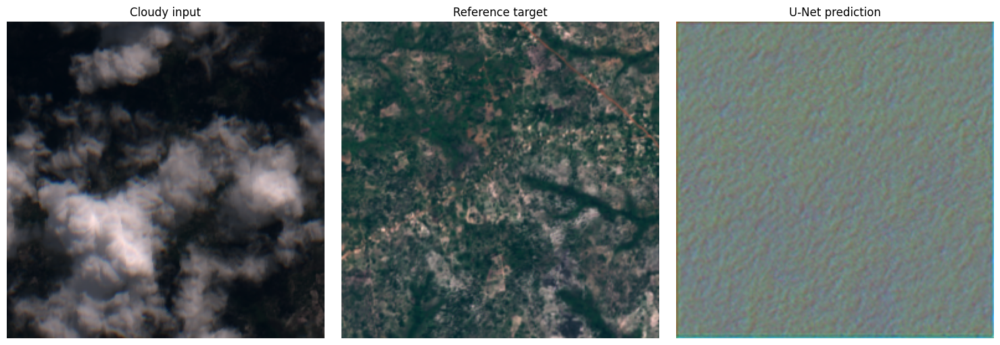

In [35]:

import torch
import matplotlib.pyplot as plt

checkpoint_path = (
    "/content/drive/MyDrive/DL/Dataset/"
    "sen12mscr_200/best_unet_baseline.pth"
)

# Load the best trained checkpoint
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best epoch:", checkpoint["epoch"])
print("Validation MSE:", checkpoint["val_mse"])

# Correctly retrieve tensors from the dictionary
batch = next(iter(val_loader))
inputs = batch["input"].to(device)
targets = batch["target"]

# Predict
with torch.no_grad():
    predictions = model(inputs)

# Convert the first sample from CHW to HWC
cloudy = inputs[0, :13].cpu().numpy().transpose(1, 2, 0)
target = targets[0].cpu().numpy().transpose(1, 2, 0)
pred = predictions[0].cpu().numpy().transpose(1, 2, 0)

# Display false-color composite using bands 4, 3, 2
def false_color(image):
    rgb = image[:, :, [3, 2, 1]]
    lo, hi = rgb.min(), rgb.max()
    return ((rgb - lo) / (hi - lo + 1e-8)).clip(0, 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(false_color(cloudy))
axes[0].set_title("Cloudy input")

axes[1].imshow(false_color(target))
axes[1].set_title("Reference target")

axes[2].imshow(false_color(pred))
axes[2].set_title("U-Net prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [36]:
import torch
import os

checkpoint_path = "/content/drive/MyDrive/DL/Dataset/sen12mscr_200/best_unet_baseline.pth"

# Load the best checkpoint from our previous 3 epochs
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])

# Restore optimizer state so training continues smoothly
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

best_val_mse = checkpoint["val_mse"]
best_epoch = checkpoint["epoch"]

print(f"Resuming from epoch: {best_epoch}")
print(f"Best validation MSE so far: {best_val_mse:.6f}")

# Train until we reach epoch 10
num_epochs = 10

for epoch in range(best_epoch, num_epochs):
    model.train()
    train_loss = 0.0

    for batch in train_loader:
        inputs = batch["input"].to(device)
        targets = batch["target"].to(device)

        optimizer.zero_grad()
        predictions = model(inputs)
        loss = criterion(predictions, targets)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * inputs.size(0)

    train_loss /= len(train_loader.dataset)

    # Validation
    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for batch in val_loader:
            inputs = batch["input"].to(device)
            targets = batch["target"].to(device)

            predictions = model(inputs)
            loss = criterion(predictions, targets)

            val_loss += loss.item() * inputs.size(0)

    val_loss /= len(val_loader.dataset)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] | "
        f"Train MSE: {train_loss:.6f} | "
        f"Validation MSE: {val_loss:.6f}"
    )

    # Save only when validation performance improves
    if val_loss < best_val_mse:
        best_val_mse = val_loss
        best_epoch = epoch + 1

        torch.save({
            "epoch": best_epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_mse": best_val_mse
        }, checkpoint_path)

        print("  -> Best model updated and saved!")

print("\nTraining complete, bro! 🚀")
print(f"Best epoch: {best_epoch}")
print(f"Best validation MSE: {best_val_mse:.6f}")
print(f"Checkpoint: {checkpoint_path}")

Resuming from epoch: 3
Best validation MSE so far: 0.001409
Epoch [4/10] | Train MSE: 0.001313 | Validation MSE: 0.001349
  -> Best model updated and saved!
Epoch [5/10] | Train MSE: 0.001270 | Validation MSE: 0.001316
  -> Best model updated and saved!
Epoch [6/10] | Train MSE: 0.001248 | Validation MSE: 0.001301
  -> Best model updated and saved!
Epoch [7/10] | Train MSE: 0.001218 | Validation MSE: 0.001255
  -> Best model updated and saved!
Epoch [8/10] | Train MSE: 0.001183 | Validation MSE: 0.001226
  -> Best model updated and saved!
Epoch [9/10] | Train MSE: 0.001174 | Validation MSE: 0.001234
Epoch [10/10] | Train MSE: 0.001157 | Validation MSE: 0.001220
  -> Best model updated and saved!

Training complete, bro! 🚀
Best epoch: 10
Best validation MSE: 0.001220
Checkpoint: /content/drive/MyDrive/DL/Dataset/sen12mscr_200/best_unet_baseline.pth


Best epoch: 10
Validation MSE: 0.001220


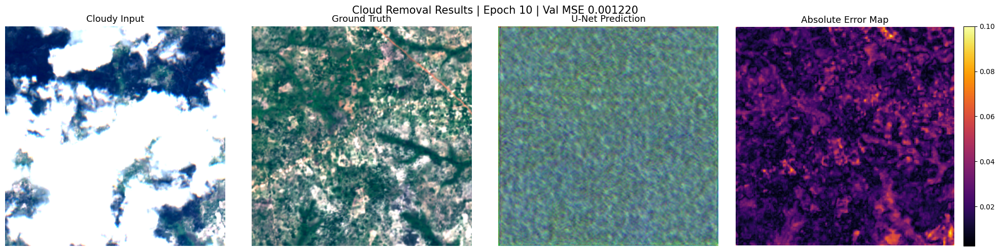

In [37]:

import torch
import numpy as np
import matplotlib.pyplot as plt

checkpoint_path = (
    "/content/drive/MyDrive/DL/Dataset/"
    "sen12mscr_200/best_unet_baseline.pth"
)

# 1. Load the best trained model
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best epoch:", checkpoint["epoch"])
print(f"Validation MSE: {checkpoint['val_mse']:.6f}")

# 2. Get a validation batch
batch = next(iter(val_loader))
inputs = batch["input"].to(device)
targets = batch["target"].to(device)

# 3. Predict cloud-free optical image
with torch.no_grad():
    predictions = model(inputs)

# Select the first validation sample
cloudy = inputs[0, :13].cpu().numpy().transpose(1, 2, 0)
target = targets[0].cpu().numpy().transpose(1, 2, 0)
pred = predictions[0].cpu().numpy().transpose(1, 2, 0)

# 4. Display bands 4, 3, 2 as a false-color composite
# Confirm band ordering against the dataset documentation.
def false_color(image, reference=None):
    rgb = image[:, :, [3, 2, 1]]

    # Use the same display scale for all three images
    if reference is None:
        lo, hi = np.percentile(rgb, [2, 98])
    else:
        ref_rgb = reference[:, :, [3, 2, 1]]
        lo, hi = np.percentile(ref_rgb, [2, 98])

    return np.clip((rgb - lo) / (hi - lo + 1e-8), 0, 1)

cloudy_rgb = false_color(cloudy, target)
target_rgb = false_color(target, target)
pred_rgb = false_color(pred, target)

# 5. Calculate per-pixel absolute error across 13 bands
error_map = np.mean(np.abs(pred - target), axis=2)

# 6. Plot results
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(cloudy_rgb)
axes[0].set_title("Cloudy Input", fontsize=13)

axes[1].imshow(target_rgb)
axes[1].set_title("Ground Truth", fontsize=13)

axes[2].imshow(pred_rgb)
axes[2].set_title("U-Net Prediction", fontsize=13)

im = axes[3].imshow(error_map, cmap="inferno")
axes[3].set_title("Absolute Error Map", fontsize=13)
plt.colorbar(im, ax=axes[3], fraction=0.046, pad=0.04)

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"Cloud Removal Results | Epoch {checkpoint['epoch']} "
    f"| Val MSE {checkpoint['val_mse']:.6f}",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [38]:

import torch

checkpoint_path = (
    "/content/drive/MyDrive/DL/Dataset/"
    "sen12mscr_200/best_unet_baseline.pth"
)

# Resume from the best saved checkpoint
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

best_val_mse = checkpoint["val_mse"]
best_epoch = checkpoint["epoch"]

print("Resuming from best epoch:", best_epoch)
print(f"Best validation MSE: {best_val_mse:.6f}")

num_epochs = 40

for epoch in range(best_epoch, num_epochs):
    # Training
    model.train()
    train_loss = 0.0

    for batch in train_loader:
        inputs = batch["input"].to(device)
        targets = batch["target"].to(device)

        optimizer.zero_grad()
        predictions = model(inputs)
        loss = criterion(predictions, targets)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * inputs.size(0)

    train_loss /= len(train_loader.dataset)

    # Validation
    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for batch in val_loader:
            inputs = batch["input"].to(device)
            targets = batch["target"].to(device)

            predictions = model(inputs)
            loss = criterion(predictions, targets)

            val_loss += loss.item() * inputs.size(0)

    val_loss /= len(val_loader.dataset)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] | "
        f"Train MSE: {train_loss:.6f} | "
        f"Validation MSE: {val_loss:.6f}"
    )

    # Save best model
    if val_loss < best_val_mse:
        best_val_mse = val_loss
        best_epoch = epoch + 1

        torch.save({
            "epoch": best_epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_mse": best_val_mse
        }, checkpoint_path)

        print("  -> Best checkpoint saved!")

print("\nTraining complete, bro! 🚀")
print("Best epoch:", best_epoch)
print(f"Best validation MSE: {best_val_mse:.6f}")


Resuming from best epoch: 10
Best validation MSE: 0.001220
Epoch [11/40] | Train MSE: 0.001170 | Validation MSE: 0.001218
  -> Best checkpoint saved!
Epoch [12/40] | Train MSE: 0.001131 | Validation MSE: 0.001201
  -> Best checkpoint saved!
Epoch [13/40] | Train MSE: 0.001116 | Validation MSE: 0.001162
  -> Best checkpoint saved!
Epoch [14/40] | Train MSE: 0.001108 | Validation MSE: 0.001157
  -> Best checkpoint saved!
Epoch [15/40] | Train MSE: 0.001083 | Validation MSE: 0.001141
  -> Best checkpoint saved!
Epoch [16/40] | Train MSE: 0.001069 | Validation MSE: 0.001161
Epoch [17/40] | Train MSE: 0.001088 | Validation MSE: 0.001122
  -> Best checkpoint saved!
Epoch [18/40] | Train MSE: 0.001067 | Validation MSE: 0.001118
  -> Best checkpoint saved!
Epoch [19/40] | Train MSE: 0.001055 | Validation MSE: 0.001117
  -> Best checkpoint saved!
Epoch [20/40] | Train MSE: 0.001060 | Validation MSE: 0.001116
  -> Best checkpoint saved!
Epoch [21/40] | Train MSE: 0.001077 | Validation MSE: 0.001

Best epoch: 35
Validation MSE: 0.000968


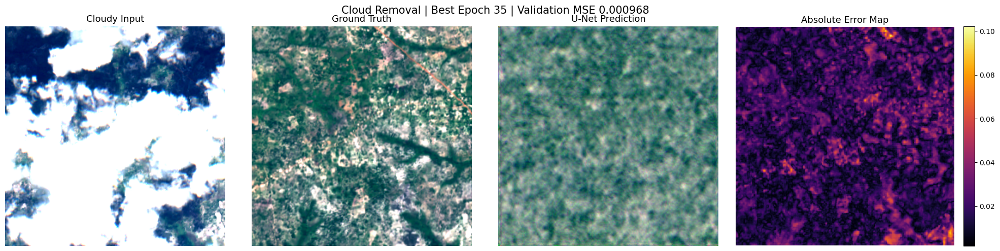

In [39]:

import torch
import numpy as np
import matplotlib.pyplot as plt

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best epoch:", checkpoint["epoch"])
print(f"Validation MSE: {checkpoint['val_mse']:.6f}")

# Get one validation batch
batch = next(iter(val_loader))
inputs = batch["input"].to(device)
targets = batch["target"].to(device)

with torch.no_grad():
    predictions = model(inputs)

# Convert CHW to HWC for visualization
cloudy = inputs[0, :13].cpu().numpy().transpose(1, 2, 0)
target = targets[0].cpu().numpy().transpose(1, 2, 0)
pred = predictions[0].cpu().numpy().transpose(1, 2, 0)

# Consistent reference-based stretch
def false_color(image, reference):
    rgb = image[:, :, [3, 2, 1]]
    ref_rgb = reference[:, :, [3, 2, 1]]

    lo, hi = np.percentile(ref_rgb, [2, 98])
    return np.clip((rgb - lo) / (hi - lo + 1e-8), 0, 1)

cloudy_rgb = false_color(cloudy, target)
target_rgb = false_color(target, target)
pred_rgb = false_color(pred, target)

# Mean absolute error across all 13 bands
error_map = np.mean(np.abs(pred - target), axis=2)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(cloudy_rgb)
axes[0].set_title("Cloudy Input", fontsize=13)

axes[1].imshow(target_rgb)
axes[1].set_title("Ground Truth", fontsize=13)

axes[2].imshow(pred_rgb)
axes[2].set_title("U-Net Prediction", fontsize=13)

im = axes[3].imshow(error_map, cmap="inferno")
axes[3].set_title("Absolute Error Map", fontsize=13)
plt.colorbar(im, ax=axes[3], fraction=0.046, pad=0.04)

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"Cloud Removal | Best Epoch {checkpoint['epoch']} "
    f"| Validation MSE {checkpoint['val_mse']:.6f}",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [40]:
#70 epochs

import torch

checkpoint_path = (
    "/content/drive/MyDrive/DL/Dataset/"
    "sen12mscr_200/best_unet_baseline.pth"
)

# Load the best checkpoint available
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

best_val_mse = checkpoint["val_mse"]
best_epoch = checkpoint["epoch"]

print("Starting from saved best epoch:", best_epoch)
print(f"Best validation MSE so far: {best_val_mse:.6f}")

num_epochs = 70

for epoch in range(best_epoch, num_epochs):
    # Training phase
    model.train()
    train_loss = 0.0

    for batch in train_loader:
        inputs = batch["input"].to(device)
        targets = batch["target"].to(device)

        optimizer.zero_grad()
        predictions = model(inputs)
        loss = criterion(predictions, targets)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * inputs.size(0)

    train_loss /= len(train_loader.dataset)

    # Validation phase
    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for batch in val_loader:
            inputs = batch["input"].to(device)
            targets = batch["target"].to(device)

            predictions = model(inputs)
            loss = criterion(predictions, targets)

            val_loss += loss.item() * inputs.size(0)

    val_loss /= len(val_loader.dataset)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] | "
        f"Train MSE: {train_loss:.6f} | "
        f"Validation MSE: {val_loss:.6f}"
    )

    # Save only when validation MSE improves
    if val_loss < best_val_mse:
        best_val_mse = val_loss
        best_epoch = epoch + 1

        torch.save({
            "epoch": best_epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_mse": best_val_mse
        }, checkpoint_path)

        print("  -> Best checkpoint saved!")

print("\n70-epoch training run complete, bro! 🚀")
print("Best epoch:", best_epoch)
print(f"Best validation MSE: {best_val_mse:.6f}")
print("Saved checkpoint:", checkpoint_path)


Starting from saved best epoch: 35
Best validation MSE so far: 0.000968
Epoch [36/70] | Train MSE: 0.000942 | Validation MSE: 0.001006
Epoch [37/70] | Train MSE: 0.000920 | Validation MSE: 0.000959
  -> Best checkpoint saved!
Epoch [38/70] | Train MSE: 0.000922 | Validation MSE: 0.001006
Epoch [39/70] | Train MSE: 0.000923 | Validation MSE: 0.000959
Epoch [40/70] | Train MSE: 0.000903 | Validation MSE: 0.000957
  -> Best checkpoint saved!
Epoch [41/70] | Train MSE: 0.000918 | Validation MSE: 0.000958
Epoch [42/70] | Train MSE: 0.000896 | Validation MSE: 0.000944
  -> Best checkpoint saved!
Epoch [43/70] | Train MSE: 0.000895 | Validation MSE: 0.000967
Epoch [44/70] | Train MSE: 0.000917 | Validation MSE: 0.001023
Epoch [45/70] | Train MSE: 0.000919 | Validation MSE: 0.001080
Epoch [46/70] | Train MSE: 0.000931 | Validation MSE: 0.000941
  -> Best checkpoint saved!
Epoch [47/70] | Train MSE: 0.000886 | Validation MSE: 0.000940
  -> Best checkpoint saved!
Epoch [48/70] | Train MSE: 0.000

Best epoch: 67
Validation MSE: 0.000890


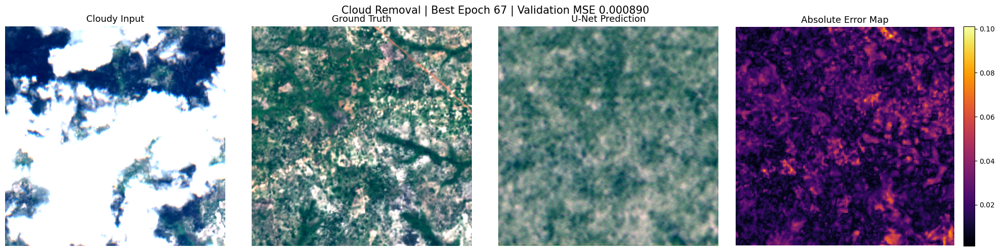

In [41]:

import torch
import numpy as np
import matplotlib.pyplot as plt

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best epoch:", checkpoint["epoch"])
print(f"Validation MSE: {checkpoint['val_mse']:.6f}")

# Get one validation batch
batch = next(iter(val_loader))
inputs = batch["input"].to(device)
targets = batch["target"].to(device)

with torch.no_grad():
    predictions = model(inputs)

# Convert CHW to HWC for visualization
cloudy = inputs[0, :13].cpu().numpy().transpose(1, 2, 0)
target = targets[0].cpu().numpy().transpose(1, 2, 0)
pred = predictions[0].cpu().numpy().transpose(1, 2, 0)

# Consistent reference-based stretch
def false_color(image, reference):
    rgb = image[:, :, [3, 2, 1]]
    ref_rgb = reference[:, :, [3, 2, 1]]

    lo, hi = np.percentile(ref_rgb, [2, 98])
    return np.clip((rgb - lo) / (hi - lo + 1e-8), 0, 1)

cloudy_rgb = false_color(cloudy, target)
target_rgb = false_color(target, target)
pred_rgb = false_color(pred, target)

# Mean absolute error across all 13 bands
error_map = np.mean(np.abs(pred - target), axis=2)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(cloudy_rgb)
axes[0].set_title("Cloudy Input", fontsize=13)

axes[1].imshow(target_rgb)
axes[1].set_title("Ground Truth", fontsize=13)

axes[2].imshow(pred_rgb)
axes[2].set_title("U-Net Prediction", fontsize=13)

im = axes[3].imshow(error_map, cmap="inferno")
axes[3].set_title("Absolute Error Map", fontsize=13)
plt.colorbar(im, ax=axes[3], fraction=0.046, pad=0.04)

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"Cloud Removal | Best Epoch {checkpoint['epoch']} "
    f"| Validation MSE {checkpoint['val_mse']:.6f}",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [42]:

import torch
import numpy as np
import pandas as pd
from skimage.metrics import structural_similarity, peak_signal_noise_ratio

checkpoint_path = (
    "/content/drive/MyDrive/DL/Dataset/"
    "sen12mscr_200/best_unet_baseline.pth"
)

# Load best saved model
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

all_metrics = []

with torch.no_grad():
    for batch_idx, batch in enumerate(val_loader):
        inputs = batch["input"].to(device)
        targets = batch["target"].to(device)

        predictions = model(inputs)

        # Evaluate each image independently across all 13 bands
        for i in range(targets.shape[0]):
            pred = predictions[i].cpu().numpy()
            target = targets[i].cpu().numpy()

            # Shapes are (13, H, W)
            mae = np.mean(np.abs(pred - target))
            mse = np.mean((pred - target) ** 2)

            # Fixed data range for normalized optical data
            psnr = peak_signal_noise_ratio(
                target, pred, data_range=1.0
            )

            # SSIM computed independently for each band,
            # then averaged across the 13 bands
            band_ssim = []
            for band in range(target.shape[0]):
                band_ssim.append(
                    structural_similarity(
                        target[band],
                        pred[band],
                        data_range=1.0
                    )
                )

            ssim = float(np.mean(band_ssim))

            all_metrics.append({
                "MAE": mae,
                "MSE": mse,
                "PSNR_dB": psnr,
                "SSIM": ssim
            })

# Summary across validation images
df_metrics = pd.DataFrame(all_metrics)

print("Best checkpoint epoch:", checkpoint["epoch"])
print(f"Saved validation MSE: {checkpoint['val_mse']:.6f}")
print("Number of validation images:", len(df_metrics))
print("\nMean validation metrics:")
print(df_metrics.mean().round(6))

print("\nStandard deviation across images:")
print(df_metrics.std().round(6))

# Save per-image results to Google Drive
results_path = (
    "/content/drive/MyDrive/DL/Dataset/"
    "sen12mscr_200/validation_metrics.csv"
)

df_metrics.to_csv(results_path, index=False)
print("\nPer-image metrics saved to:", results_path)


Best checkpoint epoch: 67
Saved validation MSE: 0.000890
Number of validation images: 40

Mean validation metrics:
MAE         0.020479
MSE         0.000890
PSNR_dB    30.625440
SSIM        0.815025
dtype: float64

Standard deviation across images:
MAE        0.002606
MSE        0.000220
PSNR_dB    1.027002
SSIM       0.027724
dtype: float64

Per-image metrics saved to: /content/drive/MyDrive/DL/Dataset/sen12mscr_200/validation_metrics.csv


In [43]:

import numpy as np
import pandas as pd
from skimage.metrics import structural_similarity, peak_signal_noise_ratio

model.eval()
comparison = []

with torch.no_grad():
    for batch in val_loader:
        inputs = batch["input"].to(device)
        targets = batch["target"].to(device)
        predictions = model(inputs)

        for i in range(targets.shape[0]):
            target = targets[i].cpu().numpy()       # (13,H,W)
            cloudy = inputs[i, :13].cpu().numpy()  # (13,H,W)
            pred = predictions[i].cpu().numpy()    # (13,H,W)

            row = {}

            for name, image in [
                ("Cloudy", cloudy),
                ("UNet", pred)
            ]:
                row[f"{name}_MAE"] = np.mean(
                    np.abs(image - target)
                )
                row[f"{name}_MSE"] = np.mean(
                    (image - target) ** 2
                )
                row[f"{name}_PSNR"] = peak_signal_noise_ratio(
                    target, image, data_range=1.0
                )

                band_ssim = [
                    structural_similarity(
                        target[b], image[b], data_range=1.0
                    )
                    for b in range(target.shape[0])
                ]
                row[f"{name}_SSIM"] = np.mean(band_ssim)

            comparison.append(row)

df_compare = pd.DataFrame(comparison)

summary = df_compare.mean().to_frame("Mean").round(6)
print(summary)

print("\nMAE reduction (%):")
print(
    100 * (
        1 - df_compare["UNet_MAE"].mean()
        / (df_compare["Cloudy_MAE"].mean() + 1e-12)
    )
)

print("\nMSE reduction (%):")
print(
    100 * (
        1 - df_compare["UNet_MSE"].mean()
        / (df_compare["Cloudy_MSE"].mean() + 1e-12)
    )
)

compare_path = (
    "/content/drive/MyDrive/DL/Dataset/"
    "sen12mscr_200/cloudy_vs_unet_metrics.csv"
)
df_compare.to_csv(compare_path, index=False)
print("\nComparison saved to:", compare_path)


                  Mean
Cloudy_MAE    0.117503
Cloudy_MSE    0.033139
Cloudy_PSNR  15.494770
Cloudy_SSIM   0.524901
UNet_MAE      0.020479
UNet_MSE      0.000890
UNet_PSNR    30.625440
UNet_SSIM     0.815025

MAE reduction (%):
82.571304

MSE reduction (%):
97.31291

Comparison saved to: /content/drive/MyDrive/DL/Dataset/sen12mscr_200/cloudy_vs_unet_metrics.csv


NEW APPORACH

In [44]:

import torch
import numpy as np
import os

checkpoint_path = (
    "/content/drive/MyDrive/DL/Dataset/"
    "sen12mscr_200/best_unet_baseline.pth"
)

print("=== DEVICE ===")
print(device)

print("\n=== DATASET SIZES ===")
print("Training samples:", len(train_loader.dataset))
print("Validation samples:", len(val_loader.dataset))

print("\n=== MODEL ===")
print("Model parameters:", sum(
    p.numel() for p in model.parameters()
))
print("Checkpoint exists:", os.path.exists(checkpoint_path))

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)
print("Best saved epoch:", checkpoint["epoch"])
print("Best saved validation MSE:", checkpoint["val_mse"])

print("\n=== INPUT / TARGET CHECK ===")
batch = next(iter(train_loader))

for key, tensor in batch.items():
    print(
        key,
        "| shape:", tuple(tensor.shape),
        "| dtype:", tensor.dtype,
        "| min:", tensor.min().item(),
        "| max:", tensor.max().item(),
        "| mean:", tensor.float().mean().item(),
        "| std:", tensor.float().std().item()
    )

print("\n=== OPTICAL AND SAR RANGES ===")
inputs = batch["input"]

optical = inputs[:, :13]
sar = inputs[:, 13:]

for name, tensor in [
    ("Optical input", optical),
    ("SAR input", sar),
    ("Optical target", batch["target"])
]:
    print(
        f"{name}: min={tensor.min().item():.4f}, "
        f"max={tensor.max().item():.4f}, "
        f"mean={tensor.float().mean().item():.4f}, "
        f"std={tensor.float().std().item():.4f}"
    )


=== DEVICE ===
cuda

=== DATASET SIZES ===
Training samples: 160
Validation samples: 40

=== MODEL ===
Model parameters: 1929453
Checkpoint exists: True
Best saved epoch: 67
Best saved validation MSE: 0.0008904663030989468

=== INPUT / TARGET CHECK ===
input | shape: (4, 15, 256, 256) | dtype: torch.float32 | min: -28.971097946166992 | max: 1.1859999895095825 | mean: -1.6434922218322754 | std: 4.9190263748168945
target | shape: (4, 13, 256, 256) | dtype: torch.float32 | min: 0.0005000000237487257 | max: 0.5623999834060669 | mean: 0.169621080160141 | std: 0.10916400700807571

=== OPTICAL AND SAR RANGES ===
Optical input: min=0.0004, max=1.1860, mean=0.2144, std=0.1648
SAR input: min=-28.9711, max=-0.7121, mean=-13.7196, std=3.6099
Optical target: min=0.0005, max=0.5624, mean=0.1696, std=0.1092


In [45]:

import torch

sar_sum = 0.0
sar_sq_sum = 0.0
sar_count = 0

for batch in train_loader:
    sar = batch["input"][:, 13:, :, :].float()

    sar_sum += sar.sum(dim=(0, 2, 3))
    sar_sq_sum += (sar ** 2).sum(dim=(0, 2, 3))
    sar_count += sar.shape[0] * sar.shape[2] * sar.shape[3]

sar_mean = sar_sum / sar_count
sar_var = (sar_sq_sum / sar_count) - sar_mean ** 2
sar_std = torch.sqrt(sar_var.clamp_min(1e-12))

print("Training-only SAR statistics")
for i in range(2):
    print(
        f"SAR channel {i}: "
        f"mean={sar_mean[i].item():.5f}, "
        f"std={sar_std[i].item():.5f}"
    )


Training-only SAR statistics
SAR channel 0: mean=-10.75813, std=2.01875
SAR channel 1: mean=-16.63421, std=2.09201


In [46]:

from torch.utils.data import Dataset, DataLoader
import torch

class SARNormalizedDataset(Dataset):
    def __init__(self, original_dataset, sar_mean, sar_std):
        self.original_dataset = original_dataset
        self.sar_mean = torch.tensor(
            sar_mean, dtype=torch.float32
        ).view(2, 1, 1)

        self.sar_std = torch.tensor(
            sar_std, dtype=torch.float32
        ).view(2, 1, 1)

    def __len__(self):
        return len(self.original_dataset)

    def __getitem__(self, idx):
        sample = self.original_dataset[idx]

        # Copy so we don't modify the original sample
        inputs = sample["input"].clone()
        target = sample["target"]

        # Standardize only the two SAR channels
        inputs[13:15] = (
            inputs[13:15] - self.sar_mean
        ) / self.sar_std

        return {
            "input": inputs,
            "target": target
        }

sar_mean_values = [-10.75813, -16.63421]
sar_std_values = [2.01875, 2.09201]

train_dataset_norm = SARNormalizedDataset(
    train_loader.dataset,
    sar_mean_values,
    sar_std_values
)

val_dataset_norm = SARNormalizedDataset(
    val_loader.dataset,
    sar_mean_values,
    sar_std_values
)

train_loader_norm = DataLoader(
    train_dataset_norm,
    batch_size=4,
    shuffle=True,
    num_workers=0
)

val_loader_norm = DataLoader(
    val_dataset_norm,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

# Verify the transformation
batch = next(iter(train_loader_norm))
inputs = batch["input"]

print("Input shape:", tuple(inputs.shape))
print("Optical mean:", inputs[:, :13].mean().item())
print("Normalized SAR means:", inputs[:, 13:].mean(dim=(0, 2, 3)))
print("Normalized SAR stds:", inputs[:, 13:].std(dim=(0, 2, 3)))
print("Target shape:", tuple(batch["target"].shape))


Input shape: (4, 15, 256, 256)
Optical mean: 0.25187766551971436
Normalized SAR means: tensor([0.2332, 0.1666])
Normalized SAR stds: tensor([1.0276, 0.9921])
Target shape: (4, 13, 256, 256)


In [47]:

import torch
import torch.nn as nn
import torch.nn.functional as F


class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class SelectiveFusion(nn.Module):
    def __init__(self, channels):
        super().__init__()

        self.gate = nn.Sequential(
            nn.Conv2d(channels * 2, channels, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels, 1),
            nn.Sigmoid()
        )

        self.project = nn.Conv2d(channels * 2, channels, 1)

    def forward(self, optical_features, sar_features):
        combined = torch.cat(
            [optical_features, sar_features], dim=1
        )

        gate = self.gate(combined)

        # Gate controls SAR contribution spatially and by channel
        fused = torch.cat(
            [optical_features, gate * sar_features], dim=1
        )

        return self.project(fused), gate


class SelectiveFusionUNet(nn.Module):
    def __init__(self, out_channels=13, base=32):
        super().__init__()

        # Optical branch: 13 bands
        self.opt1 = ConvBlock(13, base)
        self.opt2 = ConvBlock(base, base * 2)
        self.opt3 = ConvBlock(base * 2, base * 4)

        # SAR branch: 2 bands
        self.sar1 = ConvBlock(2, base)
        self.sar2 = ConvBlock(base, base * 2)
        self.sar3 = ConvBlock(base * 2, base * 4)

        self.pool = nn.MaxPool2d(2)

        # Separate selective fusion at three resolutions
        self.fuse1 = SelectiveFusion(base)
        self.fuse2 = SelectiveFusion(base * 2)
        self.fuse3 = SelectiveFusion(base * 4)

        self.bottleneck = ConvBlock(base * 4, base * 8)

        self.up3 = nn.ConvTranspose2d(
            base * 8, base * 4, 2, stride=2
        )
        self.dec3 = ConvBlock(base * 8, base * 4)

        self.up2 = nn.ConvTranspose2d(
            base * 4, base * 2, 2, stride=2
        )
        self.dec2 = ConvBlock(base * 4, base * 2)

        self.up1 = nn.ConvTranspose2d(
            base * 2, base, 2, stride=2
        )
        self.dec1 = ConvBlock(base * 2, base)

        self.output = nn.Conv2d(base, out_channels, 1)

    def forward(self, x, return_gates=False):
        optical = x[:, :13]
        sar = x[:, 13:15]

        # Encoder level 1
        o1 = self.opt1(optical)
        s1 = self.sar1(sar)
        f1, g1 = self.fuse1(o1, s1)

        # Encoder level 2
        o2 = self.opt2(self.pool(o1))
        s2 = self.sar2(self.pool(s1))
        f2, g2 = self.fuse2(o2, s2)

        # Encoder level 3
        o3 = self.opt3(self.pool(o2))
        s3 = self.sar3(self.pool(s2))
        f3, g3 = self.fuse3(o3, s3)

        # Decoder
        b = self.bottleneck(self.pool(f3))

        d3 = self.up3(b)
        d3 = self.dec3(torch.cat([d3, f3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, f2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, f1], dim=1))

        prediction = self.output(d1)

        if return_gates:
            return prediction, (g1, g2, g3)

        return prediction


# Initialize the experimental model
model_sf = SelectiveFusionUNet(
    out_channels=13,
    base=32
).to(device)

print("Model initialized successfully.")
print(
    "Parameters:",
    f"{sum(p.numel() for p in model_sf.parameters()):,}"
)

# Shape test only; no training
test_batch = next(iter(train_loader_norm))
test_input = test_batch["input"].to(device)

model_sf.eval()
with torch.no_grad():
    test_prediction, gates = model_sf(
        test_input, return_gates=True
    )

print("Input shape:", tuple(test_input.shape))
print("Prediction shape:", tuple(test_prediction.shape))
print("Gate shapes:", [tuple(g.shape) for g in gates])

assert test_prediction.shape == (
    test_input.shape[0], 13, 256, 256
)
print("Shape test passed!")


Model initialized successfully.
Parameters: 2,327,501
Input shape: (4, 15, 256, 256)
Prediction shape: (4, 13, 256, 256)
Gate shapes: [(4, 32, 256, 256), (4, 64, 128, 128), (4, 128, 64, 64)]
Shape test passed!


In [50]:

import os
import torch
import torch.nn as nn
from torch.optim import Adam

experiment_path = (
    "/content/drive/MyDrive/DL/Dataset/"
    "sen12mscr_200/best_selective_fusion_unet.pth"
)

criterion = nn.MSELoss()
optimizer_sf = Adam(model_sf.parameters(), lr=1e-4)

num_epochs = 40
best_val_mse_sf = float("inf")
best_epoch_sf = 0

for epoch in range(num_epochs):
    model_sf.train()
    train_loss_sum = 0.0
    train_pixels = 0

    for batch in train_loader_norm:
        inputs = batch["input"].to(device)
        targets = batch["target"].to(device)

        optimizer_sf.zero_grad(set_to_none=True)

        predictions = model_sf(inputs)
        loss = criterion(predictions, targets)

        loss.backward()
        optimizer_sf.step()

        n = inputs.shape[0]
        train_loss_sum += loss.item() * n
        train_pixels += n

    train_mse = train_loss_sum / train_pixels

    model_sf.eval()
    val_loss_sum = 0.0
    val_samples = 0

    with torch.no_grad():
        for batch in val_loader_norm:
            inputs = batch["input"].to(device)
            targets = batch["target"].to(device)

            predictions = model_sf(inputs)
            loss = criterion(predictions, targets)

            n = inputs.shape[0]
            val_loss_sum += loss.item() * n
            val_samples += n

    val_mse = val_loss_sum / val_samples

    if val_mse < best_val_mse_sf:
        best_val_mse_sf = val_mse
        best_epoch_sf = epoch + 1

        torch.save({
            "epoch": best_epoch_sf,
            "model_state_dict": model_sf.state_dict(),
            "optimizer_state_dict": optimizer_sf.state_dict(),
            "val_mse": best_val_mse_sf
        }, experiment_path)

    print(
        f"Epoch [{epoch+1:02d}/{num_epochs}] "
        f"Train MSE: {train_mse:.6f} | "
        f"Val MSE: {val_mse:.6f} | "
        f"Best Val: {best_val_mse_sf:.6f}"
    )

print("\nTraining finished.")
print("Best epoch:", best_epoch_sf)
print("Best validation MSE:", best_val_mse_sf)
print("Checkpoint:", experiment_path)


Epoch [01/40] Train MSE: 0.004825 | Val MSE: 0.004104 | Best Val: 0.004104
Epoch [02/40] Train MSE: 0.002872 | Val MSE: 0.006357 | Best Val: 0.004104
Epoch [03/40] Train MSE: 0.001876 | Val MSE: 0.001903 | Best Val: 0.001903
Epoch [04/40] Train MSE: 0.001378 | Val MSE: 0.001439 | Best Val: 0.001439
Epoch [05/40] Train MSE: 0.001154 | Val MSE: 0.001222 | Best Val: 0.001222
Epoch [06/40] Train MSE: 0.001069 | Val MSE: 0.001084 | Best Val: 0.001084
Epoch [07/40] Train MSE: 0.001008 | Val MSE: 0.001317 | Best Val: 0.001084
Epoch [08/40] Train MSE: 0.000969 | Val MSE: 0.001225 | Best Val: 0.001084
Epoch [09/40] Train MSE: 0.000936 | Val MSE: 0.001215 | Best Val: 0.001084
Epoch [10/40] Train MSE: 0.000913 | Val MSE: 0.001010 | Best Val: 0.001010
Epoch [11/40] Train MSE: 0.000918 | Val MSE: 0.000963 | Best Val: 0.000963
Epoch [12/40] Train MSE: 0.000880 | Val MSE: 0.000887 | Best Val: 0.000887
Epoch [13/40] Train MSE: 0.000848 | Val MSE: 0.000939 | Best Val: 0.000887
Epoch [14/40] Train MSE: 

In [53]:
import torch
import os

experiment_path = (
    "/content/drive/MyDrive/DL/Dataset/"
    "sen12mscr_200/best_selective_fusion_unet.pth"
)

checkpoint = torch.load(experiment_path, map_location=device)

model_sf.load_state_dict(checkpoint["model_state_dict"])
model_sf = model_sf.to(device)
model_sf.eval()

print("Best epoch:", checkpoint["epoch"])
print("Best validation MSE:", checkpoint["val_mse"])
print("Checkpoint loaded successfully!")

Best epoch: 37
Best validation MSE: 0.0005220732855377719
Checkpoint loaded successfully!


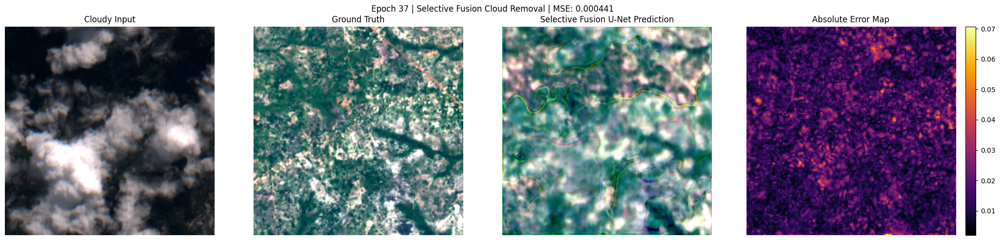

In [54]:
import numpy as np
import matplotlib.pyplot as plt
import torch

def show_selective_fusion_results(model, loader, device, epoch=None):
    model.eval()

    # Use one validation batch
    batch = next(iter(loader))
    inputs = batch["input"].to(device)
    targets = batch["target"].to(device)

    with torch.no_grad():
        predictions = model(inputs)

    # First image in the batch
    cloudy = inputs[0, :13].detach().cpu().numpy()
    target = targets[0].detach().cpu().numpy()
    pred = predictions[0].detach().cpu().numpy()

    # Standard SEN12MS band order: B4, B3, B2
    # Verify this matches your dataset's optical band order.
    rgb_indices = [3, 2, 1]

    def to_rgb(image):
        rgb = np.stack([image[i] for i in rgb_indices], axis=-1)

        # Display-only contrast stretch
        low, high = np.percentile(rgb, [2, 98])
        rgb = (rgb - low) / (high - low + 1e-8)

        return np.clip(rgb, 0, 1)

    cloudy_rgb = to_rgb(cloudy)
    target_rgb = to_rgb(target)
    pred_rgb = to_rgb(pred)

    # Mean absolute error over the 13 optical bands
    error_map = np.mean(np.abs(pred - target), axis=0)

    mse = np.mean((pred - target) ** 2)

    fig, axes = plt.subplots(1, 4, figsize=(21, 5))

    axes[0].imshow(cloudy_rgb)
    axes[0].set_title("Cloudy Input")

    axes[1].imshow(target_rgb)
    axes[1].set_title("Ground Truth")

    axes[2].imshow(pred_rgb)
    axes[2].set_title("Selective Fusion U-Net Prediction")

    im = axes[3].imshow(error_map, cmap="inferno")
    axes[3].set_title("Absolute Error Map")
    fig.colorbar(im, ax=axes[3], fraction=0.046, pad=0.04)

    for ax in axes:
        ax.axis("off")

    title = f"Selective Fusion Cloud Removal | MSE: {mse:.6f}"
    if epoch is not None:
        title = f"Epoch {epoch} | " + title

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


show_selective_fusion_results(
    model_sf,
    val_loader_norm,
    device,
    epoch=checkpoint["epoch"]
)

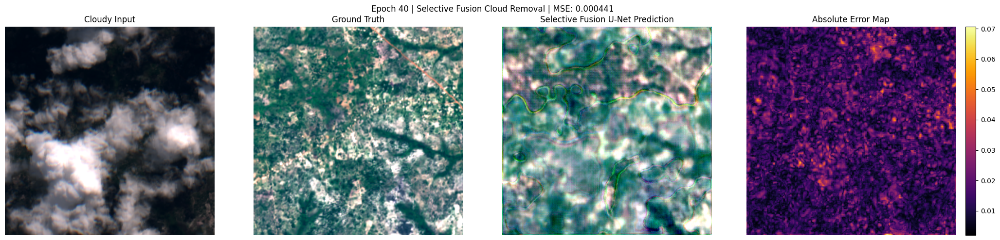

In [55]:
if (epoch + 1) % 5 == 0 or epoch == 0:
    show_selective_fusion_results(
        model_sf,
        val_loader_norm,
        device,
        epoch=epoch + 1
    )

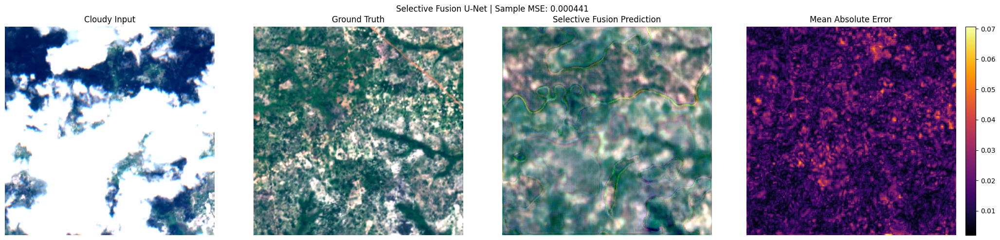

In [56]:
import numpy as np
import matplotlib.pyplot as plt
import torch

model_sf.eval()
batch = next(iter(val_loader_norm))

inputs = batch["input"].to(device)
targets = batch["target"].to(device)

with torch.no_grad():
    predictions = model_sf(inputs)

cloudy = inputs[0, :13].cpu().numpy()
target = targets[0].cpu().numpy()
pred = predictions[0].cpu().numpy()

# Standard SEN12MS band indices: B4, B3, B2.
# Verify the band order in your dataset before relying on the colors.
rgb_indices = [3, 2, 1]

def get_rgb(image):
    return np.stack([image[i] for i in rgb_indices], axis=-1)

cloudy_rgb = get_rgb(cloudy)
target_rgb = get_rgb(target)
pred_rgb = get_rgb(pred)

# Calculate display limits ONCE from ground truth.
lo, hi = np.percentile(target_rgb, [2, 98])

def apply_shared_scale(rgb):
    return np.clip((rgb - lo) / (hi - lo + 1e-8), 0, 1)

cloudy_display = apply_shared_scale(cloudy_rgb)
target_display = apply_shared_scale(target_rgb)
pred_display = apply_shared_scale(pred_rgb)

error_map = np.mean(np.abs(pred - target), axis=0)
sample_mse = np.mean((pred - target) ** 2)

fig, axes = plt.subplots(1, 4, figsize=(21, 5))

axes[0].imshow(cloudy_display)
axes[0].set_title("Cloudy Input")

axes[1].imshow(target_display)
axes[1].set_title("Ground Truth")

axes[2].imshow(pred_display)
axes[2].set_title("Selective Fusion Prediction")

im = axes[3].imshow(error_map, cmap="inferno")
axes[3].set_title("Mean Absolute Error")
fig.colorbar(im, ax=axes[3], fraction=0.046, pad=0.04)

for ax in axes:
    ax.axis("off")

fig.suptitle(f"Selective Fusion U-Net | Sample MSE: {sample_mse:.6f}")
plt.tight_layout()
plt.show()